# 🔮 Dự Đoán Giá Cổ Phiếu VN-Index bằng Mô Hình RNN Sâu
### Tiểu luận: Ứng dụng Deep Learning trong dự đoán xu hướng thị trường chứng khoán Việt Nam
---
**Mô hình chính:** Deep Stacked LSTM (5+ layers) | **Dữ liệu:** HOSE VN-Index Daily  
**So sánh:** Vanilla RNN · LSTM · GRU · Bidirectional LSTM · Deep LSTM  
**Mục tiêu:** Phân loại giá cổ phiếu tăng/giảm (Up/Down)


## 1. 📦 Cài Đặt & Import Thư Viện

> **Mục đích:** Import toàn bộ thư viện cần thiết cho quá trình:  
> - Xử lý dữ liệu (NumPy, Pandas)  
> - Trực quan hóa (Matplotlib, Seaborn, Plotly)  
> - Học máy & Deep Learning (Scikit-learn, TensorFlow/Keras)  
> - Chỉ số kỹ thuật (TA-Lib)


In [1]:
import os, warnings, json, joblib
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Scikit-learn
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, roc_auc_score, roc_curve,
                              precision_recall_curve, f1_score)
from sklearn.model_selection import train_test_split

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, LSTM, GRU, SimpleRNN, Dropout, BatchNormalization,
    Bidirectional, Input, LayerNormalization, GlobalAveragePooling1D,
    Conv1D, MaxPooling1D, Flatten, Attention
)
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint, TensorBoard)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Technical Analysis
try:
    import ta
    HAS_TA = True
    print("✅ TA library loaded")
except ImportError:
    HAS_TA = False
    print("⚠️ TA library not available – using manual indicators")

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"✅ TensorFlow: {tf.__version__}")
print(f"✅ NumPy: {np.__version__}")
print(f"✅ Pandas: {pd.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")


⚠️ TA library not available – using manual indicators
✅ TensorFlow: 2.22.0-rc0
✅ NumPy: 2.4.6
✅ Pandas: 3.0.3
GPU available: False


## 2. 📊 Tải & Khám Phá Dữ Liệu

> **Dữ liệu sử dụng:** `HOSE_DLY_VNINDEX1D.csv` — chứa dữ liệu giá đóng cửa VN-Index theo ngày từ năm 2000 đến nay.  
> **Các cột chính:** `time` (Unix timestamp), `open`, `high`, `low`, `close`, `55EMA`, `89EMA`, `200EMA`, `Volume`


In [2]:
# Đường dẫn gốc đến thư mục data
DATA_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'data')

# Load dữ liệu chính – VN-Index Daily
df_raw = pd.read_csv(os.path.join(DATA_DIR, 'HOSE_DLY_VNINDEX1D.csv'))

# Chuyển Unix timestamp thành datetime
df_raw['date'] = pd.to_datetime(df_raw['time'], unit='s')
df_raw = df_raw.sort_values('date').reset_index(drop=True)

print(f"📋 Dataset shape: {df_raw.shape}")
print(f"📅 Thời gian: {df_raw['date'].min().date()} → {df_raw['date'].max().date()}")
print(f"📊 Số phiên giao dịch: {len(df_raw):,}")
print("\n📝 Các cột:")
print(df_raw.columns.tolist())
print("\n🔍 5 dòng đầu:")
df_raw.head()


📋 Dataset shape: (6180, 10)
📅 Thời gian: 2000-07-28 → 2025-12-12
📊 Số phiên giao dịch: 6,180

📝 Các cột:
['time', 'open', 'high', 'low', 'close', '55EMA', '89EMA', '200EMA', 'Volume', 'date']

🔍 5 dòng đầu:


,time,open,high,low,close,55EMA,89EMA,200EMA,Volume,date
0,964749600,100.000000,100.000000,100.000000,100.000000,NaN,NaN,NaN,4000,2000-07-28 02:00:00
1,965008800,101.550003,101.550003,101.550003,101.550003,NaN,NaN,NaN,10000,2000-07-31 02:00:00
2,965181600,103.379997,103.379997,103.379997,103.379997,NaN,NaN,NaN,300,2000-08-02 02:00:00
3,965354400,105.199997,105.199997,105.199997,105.199997,NaN,NaN,NaN,4000,2000-08-04 02:00:00
4,965613600,106.919998,106.919998,106.919998,106.919998,NaN,NaN,NaN,13000,2000-08-07 02:00:00


## 3. 📈 Phân Tích Thám Khá (EDA)

> **Mục đích:** Hiểu phân phối dữ liệu, xu hướng giá, khối lượng giao dịch và các chỉ số kỹ thuật trước khi đưa vào mô hình.


In [3]:
# 3.1 – Thống kê mô tả
print("=== THỐNG KÊ MÔ TẢ ===")
print(df_raw[['open','high','low','close','Volume']].describe().round(2))


=== THỐNG KÊ MÔ TẢ ===
          open     high      low    close        Volume
count  6180.00  6180.00  6180.00  6180.00  6.180000e+03
mean    688.79   693.03   684.28   688.75  2.242008e+08
std     387.26   390.16   384.04   387.32  3.284043e+08
min     100.00   100.00   100.00   100.00  3.000000e+02
25%     400.02   402.49   397.47   401.00  7.411250e+06
50%     573.56   577.04   570.14   573.20  7.756950e+07
75%     995.50   998.73   988.48   994.39  2.377690e+08
max    1766.85  1794.58  1753.50  1766.85  2.804802e+09


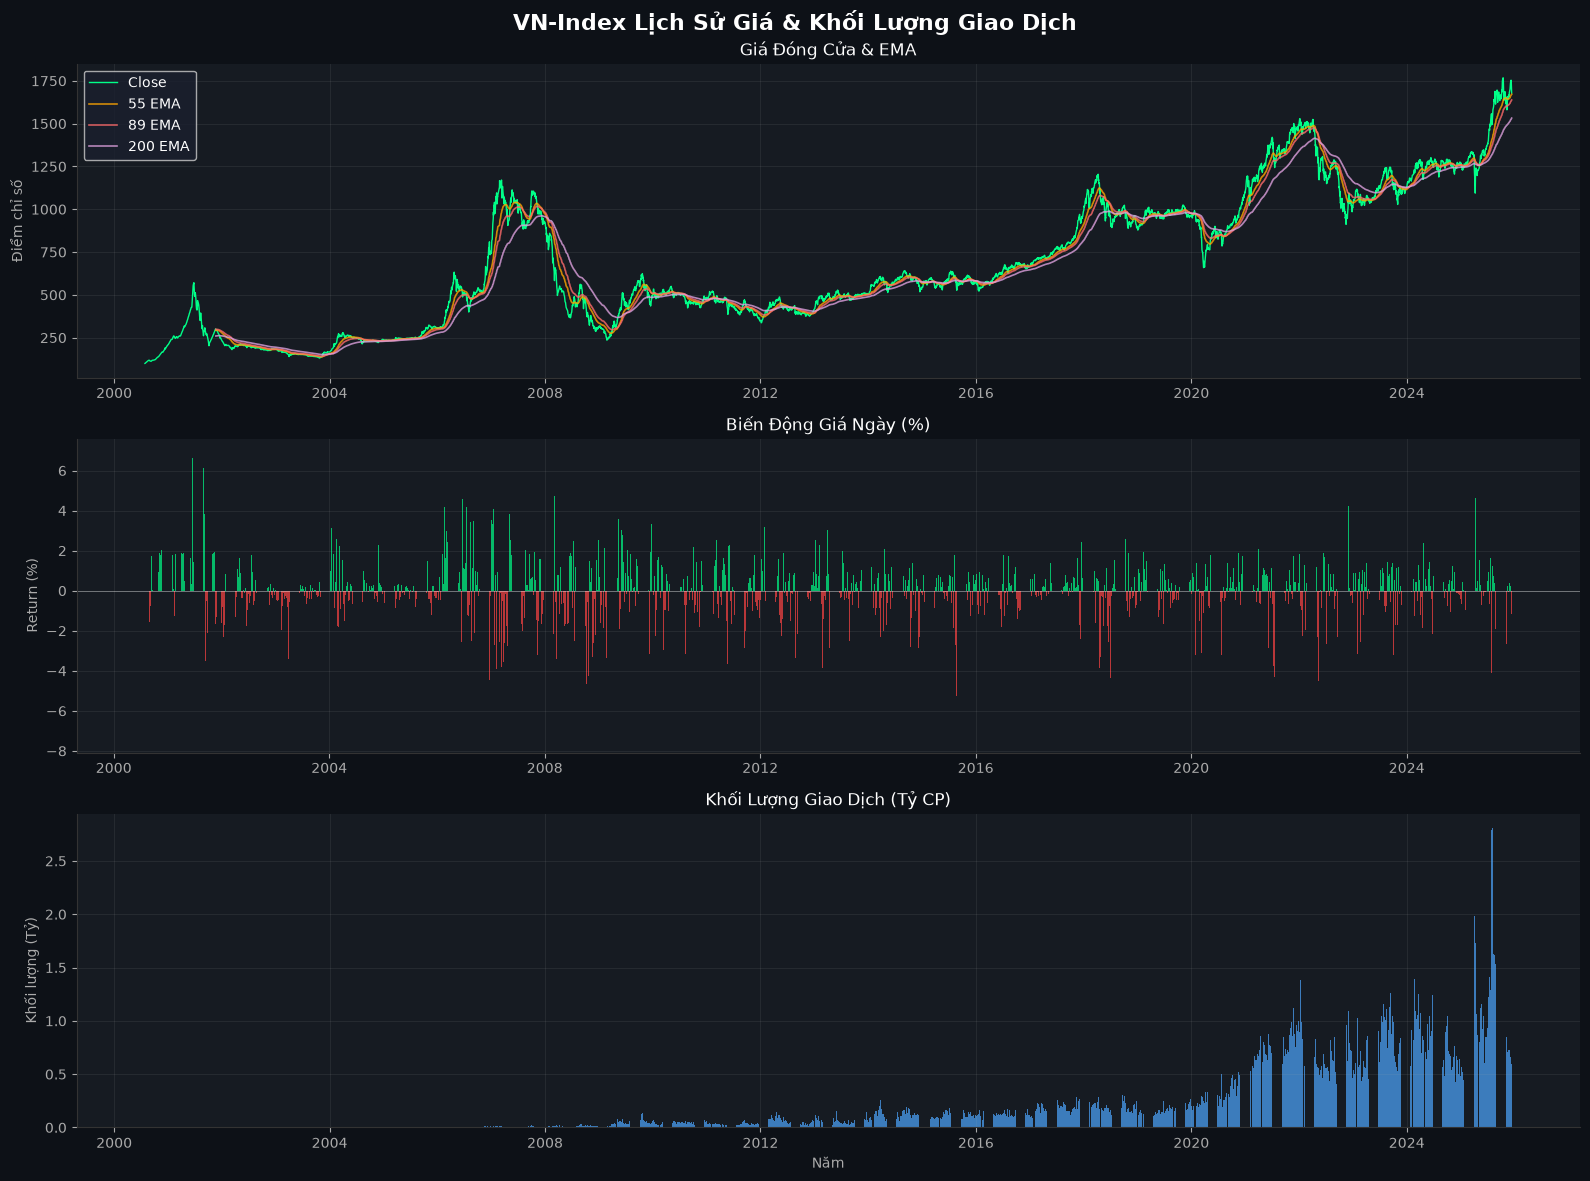

✅ Đã lưu: eda_price_history.png


In [4]:
# 3.2 – Biểu đồ lịch sử giá VN-Index
fig, axes = plt.subplots(3, 1, figsize=(16, 12), facecolor='#0d1117')
fig.suptitle('VN-Index Lịch Sử Giá & Khối Lượng Giao Dịch', 
             fontsize=16, color='white', fontweight='bold')

# Màu sắc
c_price = '#00ff88'
c_vol   = '#4da6ff'
c_ema55 = '#ffa500'
c_ema89 = '#ff6b6b'
c_ema200= '#dda0dd'

for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='#aaaaaa')
    ax.spines['bottom'].set_color('#333')
    ax.spines['left'].set_color('#333')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Giá đóng cửa + EMA
axes[0].plot(df_raw['date'], df_raw['close'], color=c_price, lw=1, label='Close')
df_ema = df_raw.dropna(subset=['55EMA','89EMA','200EMA'])
axes[0].plot(df_ema['date'], df_ema['55EMA'],  color=c_ema55,  lw=1.2, alpha=0.8, label='55 EMA')
axes[0].plot(df_ema['date'], df_ema['89EMA'],  color=c_ema89,  lw=1.2, alpha=0.8, label='89 EMA')
axes[0].plot(df_ema['date'], df_ema['200EMA'], color=c_ema200, lw=1.2, alpha=0.8, label='200 EMA')
axes[0].set_title('Giá Đóng Cửa & EMA', color='white')
axes[0].set_ylabel('Điểm chỉ số', color='#aaaaaa')
axes[0].legend(facecolor='#1a1f2e', labelcolor='white')
axes[0].grid(True, alpha=0.1)

# Biến động giá hàng ngày (%)
df_raw['daily_return'] = df_raw['close'].pct_change() * 100
colors_ret = [c_price if x >= 0 else '#ff4444' for x in df_raw['daily_return'].fillna(0)]
axes[1].bar(df_raw['date'], df_raw['daily_return'], color=colors_ret, alpha=0.7, width=1)
axes[1].axhline(0, color='white', lw=0.5, alpha=0.5)
axes[1].set_title('Biến Động Giá Ngày (%)', color='white')
axes[1].set_ylabel('Return (%)', color='#aaaaaa')
axes[1].grid(True, alpha=0.1)

# Khối lượng giao dịch
axes[2].bar(df_raw['date'], df_raw['Volume']/1e9, color=c_vol, alpha=0.7, width=1)
axes[2].set_title('Khối Lượng Giao Dịch (Tỷ CP)', color='white')
axes[2].set_ylabel('Khối lượng (Tỷ)', color='#aaaaaa')
axes[2].set_xlabel('Năm', color='#aaaaaa')
axes[2].grid(True, alpha=0.1)

plt.tight_layout()
plt.savefig('eda_price_history.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("✅ Đã lưu: eda_price_history.png")


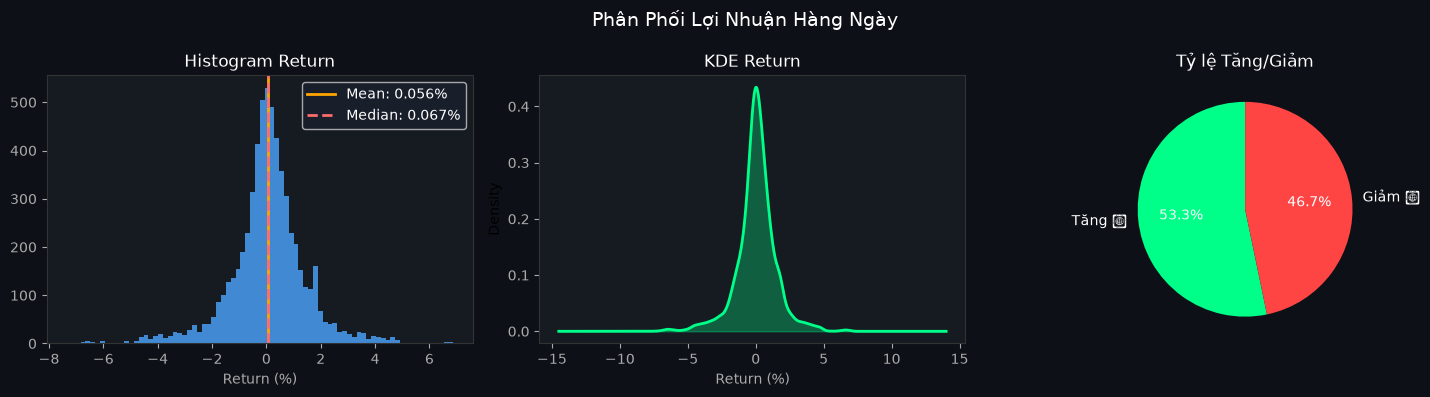

📊 Ngày Tăng: 3291 (53.3%) | Ngày Giảm: 2888 (46.7%)


In [5]:
# 3.3 – Phân phối lợi nhuận hàng ngày
fig, axes = plt.subplots(1, 3, figsize=(15, 4), facecolor='#0d1117')
fig.suptitle('Phân Phối Lợi Nhuận Hàng Ngày', fontsize=14, color='white')

ret = df_raw['daily_return'].dropna()

for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='#aaaaaa')
    for spine in ax.spines.values(): spine.set_color('#333')

# Histogram
axes[0].hist(ret, bins=80, color='#4da6ff', edgecolor='none', alpha=0.8)
axes[0].axvline(ret.mean(), color='#ffa500', lw=2, label=f'Mean: {ret.mean():.3f}%')
axes[0].axvline(ret.median(), color='#ff6b6b', lw=2, linestyle='--', label=f'Median: {ret.median():.3f}%')
axes[0].set_title('Histogram Return', color='white')
axes[0].set_xlabel('Return (%)', color='#aaaaaa')
axes[0].legend(facecolor='#1a1f2e', labelcolor='white')

# KDE
ret.plot.kde(ax=axes[1], color='#00ff88', lw=2)
axes[1].set_title('KDE Return', color='white')
axes[1].set_xlabel('Return (%)', color='#aaaaaa')
axes[1].fill_between(axes[1].lines[0].get_xdata(), axes[1].lines[0].get_ydata(), alpha=0.3, color='#00ff88')

# Biểu đồ % Up vs Down
up = (ret > 0).sum()
dn = (ret <= 0).sum()
axes[2].pie([up, dn], labels=['Tăng 📈', 'Giảm 📉'], colors=['#00ff88','#ff4444'],
            autopct='%1.1f%%', textprops={'color':'white'}, startangle=90)
axes[2].set_title('Tỷ lệ Tăng/Giảm', color='white')

plt.tight_layout()
plt.savefig('eda_return_dist.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print(f"📊 Ngày Tăng: {up} ({up/(up+dn)*100:.1f}%) | Ngày Giảm: {dn} ({dn/(up+dn)*100:.1f}%)")


## 4. 🛠️ Feature Engineering – Tạo Đặc Trưng Kỹ Thuật

> **Mục đích:** Từ dữ liệu OHLCV cơ bản, tạo thêm **33 đặc trưng kỹ thuật** giúp mô hình học được các tín hiệu giao dịch:  
> - **Trend Indicators:** EMA, SMA, MACD, ADX  
> - **Momentum Indicators:** RSI, Stochastic, Williams %R, CCI  
> - **Volatility Indicators:** Bollinger Bands, ATR, Keltner Channel  
> - **Volume Indicators:** OBV, MFI, VWAP  
> - **Price Action:** Returns, Log Returns, Candle patterns  
> - **Target:** `label` — 1 nếu giá ngày mai tăng, 0 nếu giảm


In [6]:
def compute_technical_indicators(df: pd.DataFrame) -> pd.DataFrame:
    """
    ╔══════════════════════════════════════════════════════════════════════════╗
    ║          HỢP CÁC HÀM: compute_technical_indicators                     ║
    ╠══════════════════════════════════════════════════════════════════════════╣
    ║ Bước 1: compute_returns(df)      → Tính return, log-return             ║
    ║ Bước 2: compute_moving_averages(df) → SMA/EMA nhiều chu kỳ            ║
    ║ Bước 3: compute_momentum(df)     → RSI, Stochastic, Williams %R        ║
    ║ Bước 4: compute_volatility(df)   → Bollinger Bands, ATR               ║
    ║ Bước 5: compute_volume_ind(df)   → OBV, MFI                           ║
    ║ Bước 6: compute_macd(df)        → MACD Signal                         ║
    ║ Bước 7: create_label(df)         → Nhãn phân loại Up/Down             ║
    ╚══════════════════════════════════════════════════════════════════════════╝
    
    Tham số:
        df (DataFrame): Dữ liệu OHLCV thô
    
    Trả về:
        DataFrame: Dữ liệu đã bổ sung đặc trưng kỹ thuật và nhãn
    """
    d = df.copy()
    
    # ────────────────────────────────────────────────
    # Bước 1: compute_returns – Tính lợi nhuận
    # ────────────────────────────────────────────────
    d = _compute_returns(d)
    
    # ────────────────────────────────────────────────
    # Bước 2: compute_moving_averages – Đường trung bình
    # ────────────────────────────────────────────────
    d = _compute_moving_averages(d)
    
    # ────────────────────────────────────────────────
    # Bước 3: compute_momentum – Chỉ số đà
    # ────────────────────────────────────────────────
    d = _compute_momentum(d)
    
    # ────────────────────────────────────────────────
    # Bước 4: compute_volatility – Độ biến động
    # ────────────────────────────────────────────────
    d = _compute_volatility(d)
    
    # ────────────────────────────────────────────────
    # Bước 5: compute_volume_ind – Chỉ số khối lượng
    # ────────────────────────────────────────────────
    d = _compute_volume_indicators(d)
    
    # ────────────────────────────────────────────────
    # Bước 6: compute_macd – MACD & Signal
    # ────────────────────────────────────────────────
    d = _compute_macd(d)
    
    # ────────────────────────────────────────────────
    # Bước 7: create_label – Tạo nhãn mục tiêu
    # ────────────────────────────────────────────────
    d = _create_label(d)
    
    return d


# ─────────────────────────────────────────────────────────
# HÀM CON 1: _compute_returns
# ─────────────────────────────────────────────────────────
def _compute_returns(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Tính lợi nhuận ngày (Return) và log-return
    
    - daily_return : % biến động giá mỗi ngày = (close_t - close_{t-1}) / close_{t-1} × 100
    - log_return   : Logarithm tự nhiên của tỉ lệ giá liên tiếp (ổn định hơn cho thống kê)
    - high_low_pct : Biên độ giá ngày = (high - low) / close × 100
    - open_close_pct: % biến động từ mở cửa đến đóng cửa = (close - open) / open × 100
    """
    df['daily_return']   = df['close'].pct_change() * 100
    df['log_return']     = np.log(df['close'] / df['close'].shift(1))
    df['high_low_pct']   = (df['high'] - df['low']) / df['close'] * 100
    df['open_close_pct'] = (df['close'] - df['open']) / df['open'] * 100
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 2: _compute_moving_averages
# ─────────────────────────────────────────────────────────
def _compute_moving_averages(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Tạo các đường trung bình động (SMA/EMA)
    
    SMA (Simple Moving Average): Trung bình cộng của n kỳ gần nhất
        SMA_n(t) = (1/n) × Σ close_{t-i} với i từ 0 đến n-1
    
    EMA (Exponential Moving Average): Trung bình có trọng số hàm mũ
        EMA_n(t) = close_t × α + EMA_n(t-1) × (1-α), α = 2/(n+1)
    
    Price/MA Ratio: Cho biết giá đang trên hay dưới đường MA
        → > 1.0: giá trên MA (xu hướng tăng)
        → < 1.0: giá dưới MA (xu hướng giảm)
    """
    for window in [5, 10, 20, 50]:
        df[f'sma_{window}'] = df['close'].rolling(window).mean()
        df[f'ema_{window}'] = df['close'].ewm(span=window, adjust=False).mean()
    
    # Tỷ lệ giá so với EMA – chuẩn hóa so sánh
    df['price_sma20_ratio'] = df['close'] / df['sma_20']
    df['price_ema20_ratio'] = df['close'] / df['ema_20']
    df['ema5_ema20_ratio']  = df['ema_5']  / df['ema_20']  # Golden/Death cross tín hiệu
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 3: _compute_momentum
# ─────────────────────────────────────────────────────────
def _compute_momentum(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Chỉ số đà (Momentum Indicators)
    
    RSI (Relative Strength Index):
        RS = avg(gain, 14) / avg(loss, 14)
        RSI = 100 - 100/(1+RS)
        → RSI > 70: vùng quá mua (overbought) → có thể đảo chiều giảm
        → RSI < 30: vùng quá bán (oversold)   → có thể đảo chiều tăng
    
    Stochastic %K:
        %K = (close - lowest_low_14) / (highest_high_14 - lowest_low_14) × 100
        → Đo vị trí đóng cửa trong khoảng giá 14 phiên
    
    Williams %R:
        %R = (highest_high_14 - close) / (highest_high_14 - lowest_low_14) × (-100)
        → < -80: quá bán | > -20: quá mua
    
    Rate of Change (ROC):
        ROC_n = (close_t - close_{t-n}) / close_{t-n} × 100
        → Đo tốc độ thay đổi giá
    
    CCI (Commodity Channel Index):
        CCI = (Typical Price - SMA_20) / (0.015 × Mean Deviation)
        → > 100: quá mua | < -100: quá bán
    """
    # RSI
    delta = df['close'].diff()
    gain  = delta.clip(lower=0)
    loss  = (-delta).clip(lower=0)
    avg_gain = gain.ewm(com=13, adjust=False).mean()
    avg_loss = loss.ewm(com=13, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    df['rsi_14'] = 100 - (100 / (1 + rs))
    
    # Stochastic %K
    low_14  = df['low'].rolling(14).min()
    high_14 = df['high'].rolling(14).max()
    df['stoch_k'] = (df['close'] - low_14) / (high_14 - low_14 + 1e-10) * 100
    df['stoch_d'] = df['stoch_k'].rolling(3).mean()
    
    # Williams %R
    df['williams_r'] = (high_14 - df['close']) / (high_14 - low_14 + 1e-10) * (-100)
    
    # Rate of Change
    df['roc_10'] = df['close'].pct_change(10) * 100
    df['roc_20'] = df['close'].pct_change(20) * 100
    
    # CCI
    typical_price = (df['high'] + df['low'] + df['close']) / 3
    sma_tp = typical_price.rolling(20).mean()
    mean_dev = typical_price.rolling(20).apply(lambda x: np.abs(x - x.mean()).mean())
    df['cci_20'] = (typical_price - sma_tp) / (0.015 * mean_dev + 1e-10)
    
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 4: _compute_volatility
# ─────────────────────────────────────────────────────────
def _compute_volatility(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Chỉ số biến động (Volatility Indicators)
    
    Bollinger Bands (BB):
        BB_Middle = SMA_20
        BB_Upper  = SMA_20 + 2 × std_20
        BB_Lower  = SMA_20 - 2 × std_20
        BB_Width  = (Upper - Lower) / Middle → đo độ rộng dải (biến động cao khi rộng)
        BB_pct    = (close - Lower) / (Upper - Lower) → vị trí trong dải (0-1)
    
    ATR (Average True Range):
        True Range = max(high-low, |high-close_prev|, |low-close_prev|)
        ATR_14 = EMA(True Range, 14)
        → ATR cao: thị trường biến động mạnh
        → ATR thấp: thị trường ổn định
    
    Historical Volatility:
        HV_20 = std(log_return, 20) × sqrt(252)
        → Độ lệch chuẩn lợi nhuận log trong 20 ngày, quy năm
    """
    # Bollinger Bands
    bb_sma = df['close'].rolling(20).mean()
    bb_std = df['close'].rolling(20).std()
    bb_upper = bb_sma + 2 * bb_std
    bb_lower = bb_sma - 2 * bb_std
    df['bb_width'] = (bb_upper - bb_lower) / (bb_sma + 1e-10)
    df['bb_pct']   = (df['close'] - bb_lower) / (bb_upper - bb_lower + 1e-10)
    
    # ATR
    prev_close = df['close'].shift(1)
    tr = pd.concat([
        df['high'] - df['low'],
        (df['high'] - prev_close).abs(),
        (df['low']  - prev_close).abs()
    ], axis=1).max(axis=1)
    df['atr_14'] = tr.ewm(span=14, adjust=False).mean()
    df['atr_pct'] = df['atr_14'] / df['close'] * 100  # Chuẩn hóa ATR theo %
    
    # Historical Volatility
    df['hv_20'] = df['log_return'].rolling(20).std() * np.sqrt(252)
    
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 5: _compute_volume_indicators
# ─────────────────────────────────────────────────────────
def _compute_volume_indicators(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Chỉ số khối lượng (Volume Indicators)
    
    OBV (On-Balance Volume):
        OBV_t = OBV_{t-1} + Volume nếu close > close_prev
        OBV_t = OBV_{t-1} - Volume nếu close < close_prev
        → Đo áp lực mua/bán tích lũy theo khối lượng
    
    Volume Ratio (VR):
        VR = volume_t / SMA(volume, 20)
        → > 1.5: giao dịch cao bất thường (có thể xác nhận breakout)
        → < 0.5: giao dịch thấp (thị trường ít thanh khoản)
    
    MFI (Money Flow Index):
        Tương tự RSI nhưng tích hợp thêm khối lượng
        Raw MF = Typical Price × Volume
        MFI = 100 - 100 / (1 + Positive MF / Negative MF)
    """
    # Chuẩn hóa volume
    df['volume_log']   = np.log(df['Volume'] + 1)
    df['volume_ratio'] = df['Volume'] / (df['Volume'].rolling(20).mean() + 1)
    
    # OBV
    direction = np.sign(df['close'].diff())
    df['obv'] = (direction * df['Volume']).cumsum()
    df['obv_sma'] = df['obv'].rolling(10).mean()
    
    # MFI
    typical_price = (df['high'] + df['low'] + df['close']) / 3
    raw_money_flow = typical_price * df['Volume']
    pos_mf = raw_money_flow.where(df['close'] > df['close'].shift(1), 0)
    neg_mf = raw_money_flow.where(df['close'] < df['close'].shift(1), 0)
    mf_ratio = pos_mf.rolling(14).sum() / (neg_mf.rolling(14).sum() + 1e-10)
    df['mfi_14'] = 100 - 100 / (1 + mf_ratio)
    
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 6: _compute_macd
# ─────────────────────────────────────────────────────────
def _compute_macd(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: MACD (Moving Average Convergence Divergence)
    
    MACD Line = EMA_12 - EMA_26
        → Đo sự hội tụ/phân kỳ giữa 2 đường EMA
    
    Signal Line = EMA_9(MACD)
        → Đường tín hiệu – giao cắt với MACD tạo tín hiệu mua/bán
    
    Histogram = MACD - Signal
        → Trực quan hóa khoảng cách giữa MACD và Signal
        → > 0 và tăng: momentum tăng
        → < 0 và giảm: momentum giảm
    """
    ema12 = df['close'].ewm(span=12, adjust=False).mean()
    ema26 = df['close'].ewm(span=26, adjust=False).mean()
    df['macd']        = ema12 - ema26
    df['macd_signal'] = df['macd'].ewm(span=9, adjust=False).mean()
    df['macd_hist']   = df['macd'] - df['macd_signal']
    df['macd_cross']  = np.sign(df['macd_hist'])  # +1: bullish | -1: bearish
    return df


# ─────────────────────────────────────────────────────────
# HÀM CON 7: _create_label
# ─────────────────────────────────────────────────────────
def _create_label(df: pd.DataFrame) -> pd.DataFrame:
    """
    📌 Giải thích: Tạo nhãn phân loại mục tiêu
    
    label = 1 nếu close_{t+1} > close_t  (giá ngày mai tăng → MUA)
    label = 0 nếu close_{t+1} <= close_t (giá ngày mai giảm → KHÔNG MUA)
    
    Đây là bài toán phân loại nhị phân (Binary Classification):
    → Mô hình học từ dữ liệu hôm nay để dự đoán xu hướng ngày mai
    """
    df['label'] = (df['close'].shift(-1) > df['close']).astype(int)
    return df


# ─── Áp dụng feature engineering ───
print("⚙️  Đang tính toán đặc trưng kỹ thuật...")
df_feat = compute_technical_indicators(df_raw)

# Loại bỏ dòng NaN
df_feat.dropna(inplace=True)
df_feat.reset_index(drop=True, inplace=True)

print(f"✅ Xong! Dataset sau FE: {df_feat.shape}")
print(f"📊 Số đặc trưng mới: {df_feat.shape[1] - df_raw.shape[1]}")
print(f"🎯 Phân phối nhãn: Up={df_feat['label'].sum()} ({df_feat['label'].mean()*100:.1f}%) | Down={(~df_feat['label'].astype(bool)).sum()}")


⚙️  Đang tính toán đặc trưng kỹ thuật...
✅ Xong! Dataset sau FE: (5981, 47)
📊 Số đặc trưng mới: 36
🎯 Phân phối nhãn: Up=3143 (52.5%) | Down=2838


### 4.1 Tương Quan Giữa Các Đặc Trưng

> Biểu đồ heatmap giúp xác định các đặc trưng có tương quan cao với nhau (có thể gây multicollinearity) và đặc trưng nào liên quan nhất đến nhãn `label`.


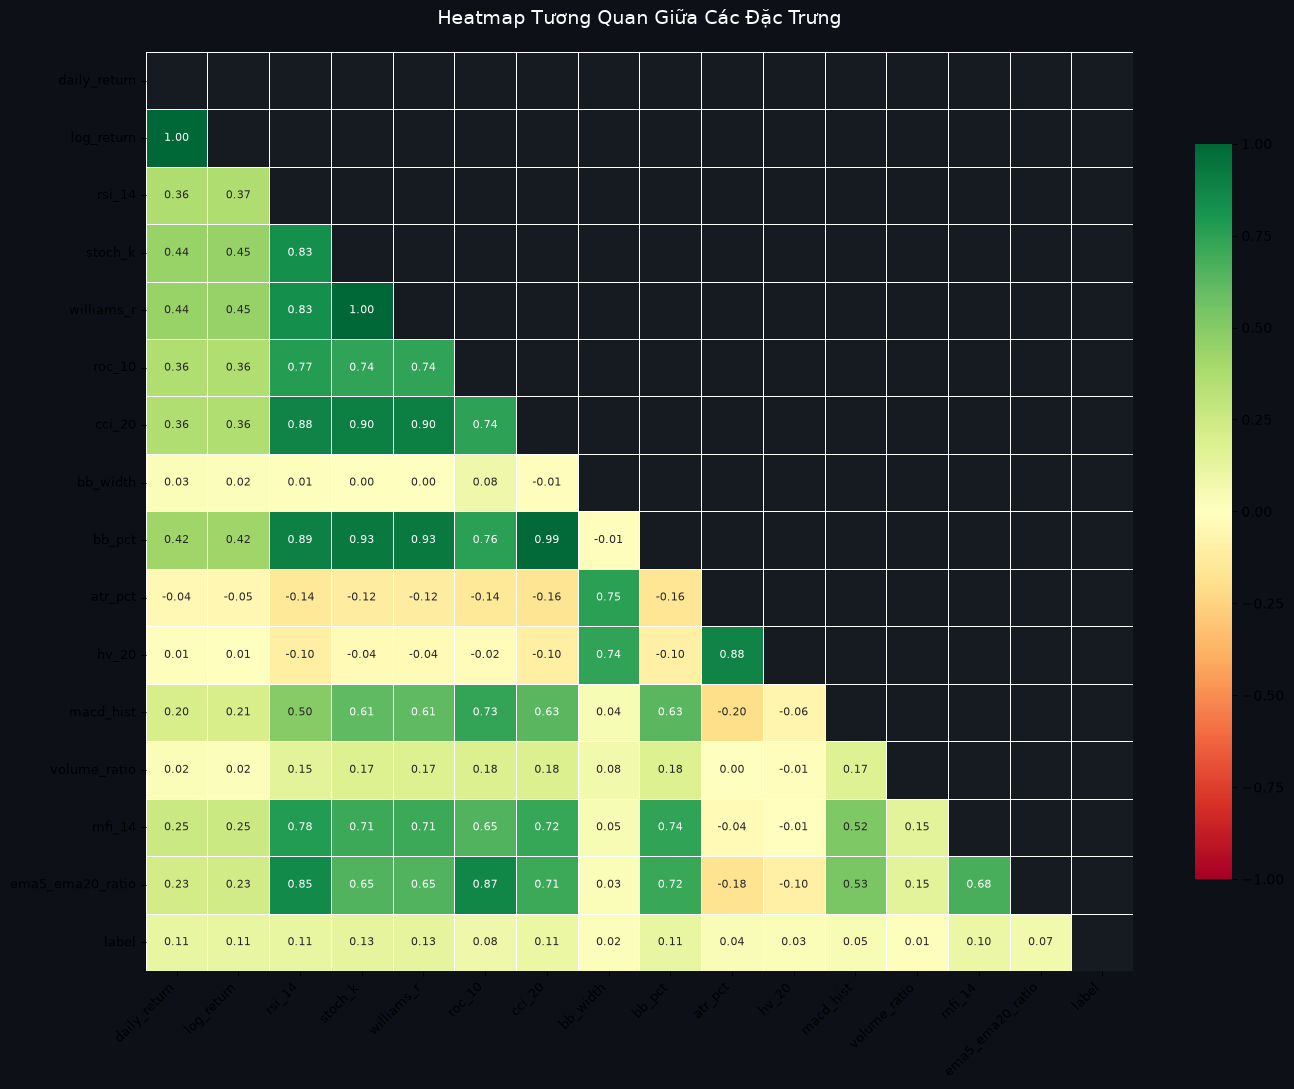


🎯 Tương quan với nhãn (label):
stoch_k             0.1250
williams_r          0.1250
bb_pct              0.1135
daily_return        0.1135
log_return          0.1128
rsi_14              0.1106
cci_20              0.1061
mfi_14              0.0979
roc_10              0.0821
ema5_ema20_ratio    0.0741
macd_hist           0.0465
atr_pct             0.0352
hv_20               0.0253
bb_width            0.0231
volume_ratio        0.0115
Name: label, dtype: float64


In [7]:
# Chọn các features để visualize
feat_cols = ['daily_return','log_return','rsi_14','stoch_k','williams_r',
             'roc_10','cci_20','bb_width','bb_pct','atr_pct','hv_20',
             'macd_hist','volume_ratio','mfi_14','ema5_ema20_ratio','label']

corr_matrix = df_feat[feat_cols].corr()

plt.figure(figsize=(14, 11), facecolor='#0d1117')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size': 8}, cbar_kws={'shrink': 0.8})
plt.title('Heatmap Tương Quan Giữa Các Đặc Trưng', fontsize=14, 
          color='white', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.gca().set_facecolor('#161b22')
plt.gcf().patch.set_facecolor('#0d1117')
plt.tight_layout()
plt.savefig('eda_correlation.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()

# Tương quan với nhãn
print("\n🎯 Tương quan với nhãn (label):")
label_corr = corr_matrix['label'].drop('label').abs().sort_values(ascending=False)
print(label_corr.round(4))


## 5. 🔄 Chuẩn Bị Dataset cho Mô Hình RNN

> **Chuỗi thời gian (Time Series):** Mô hình RNN cần dữ liệu dạng chuỗi 3D: `(samples, timesteps, features)`  
> - `samples`: Số mẫu huấn luyện  
> - `timesteps = 30`: Cửa sổ thời gian (lookback = 30 phiên trước đó)  
> - `features`: Số đặc trưng đầu vào  
>
> **Chia dữ liệu:** Train 70% | Validation 15% | Test 15% (theo thứ tự thời gian, không shuffle)


In [8]:
def prepare_sequences(df: pd.DataFrame, feature_cols: list, 
                       target_col: str, lookback: int = 30):
    """
    📌 Giải thích: Chuyển đổi chuỗi thời gian thành dạng sequences 3D
    
    Thuật toán sliding window:
    ┌─────────────────────────────────────────────┐
    │ t-29 t-28 ... t-1   t  │→│  label(t+1)     │
    │ t-28 t-27 ... t     t+1│→│  label(t+2)     │
    │ ...                    │→│  ...             │
    └─────────────────────────────────────────────┘
    
    Input shape:  (N, lookback, n_features)  ← 3D tensor
    Output shape: (N,)                        ← 1D labels
    """
    features = df[feature_cols].values
    target   = df[target_col].values
    
    X, y = [], []
    for i in range(lookback, len(features)):
        X.append(features[i - lookback : i])
        y.append(target[i])
    
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


# ─── Định nghĩa features ───
FEATURE_COLS = [
    'open','high','low','close','Volume',
    'daily_return','log_return','high_low_pct','open_close_pct',
    'sma_5','sma_10','sma_20','sma_50',
    'ema_5','ema_10','ema_20','ema_50',
    'price_sma20_ratio','price_ema20_ratio','ema5_ema20_ratio',
    'rsi_14','stoch_k','stoch_d','williams_r','roc_10','roc_20','cci_20',
    'bb_width','bb_pct','atr_14','atr_pct','hv_20',
    'macd','macd_signal','macd_hist','macd_cross',
    'volume_log','volume_ratio','obv','mfi_14'
]
TARGET_COL = 'label'
LOOKBACK   = 30

# Chuẩn hóa features bằng MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
df_feat[FEATURE_COLS] = scaler.fit_transform(df_feat[FEATURE_COLS])

# Tạo sequences
X_all, y_all = prepare_sequences(df_feat, FEATURE_COLS, TARGET_COL, LOOKBACK)
print(f"📐 Tổng shape: X={X_all.shape}, y={y_all.shape}")

# Chia train/val/test theo thứ tự thời gian (KHÔNG shuffle!)
N = len(X_all)
n_train = int(N * 0.70)
n_val   = int(N * 0.15)
n_test  = N - n_train - n_val

X_train, y_train = X_all[:n_train], y_all[:n_train]
X_val,   y_val   = X_all[n_train:n_train+n_val], y_all[n_train:n_train+n_val]
X_test,  y_test  = X_all[n_train+n_val:], y_all[n_train+n_val:]

print(f"\n📊 Phân chia dữ liệu:")
print(f"   Train : {X_train.shape} | Label: Up={y_train.sum():.0f}, Down={(~y_train.astype(bool)).sum():.0f}")
print(f"   Val   : {X_val.shape}   | Label: Up={y_val.sum():.0f}, Down={(~y_val.astype(bool)).sum():.0f}")
print(f"   Test  : {X_test.shape}  | Label: Up={y_test.sum():.0f}, Down={(~y_test.astype(bool)).sum():.0f}")

# Lưu scaler
os.makedirs('models', exist_ok=True)
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(FEATURE_COLS, 'models/feature_cols.pkl')
print("\n✅ Đã lưu scaler và feature_cols vào models/")

INPUT_SHAPE = (LOOKBACK, len(FEATURE_COLS))
N_FEATURES  = len(FEATURE_COLS)
print(f"\n🔑 Input shape cho model: {INPUT_SHAPE}")


📐 Tổng shape: X=(5951, 30, 40), y=(5951,)

📊 Phân chia dữ liệu:
   Train : (4165, 30, 40) | Label: Up=2135, Down=2030
   Val   : (892, 30, 40)   | Label: Up=502, Down=390
   Test  : (894, 30, 40)  | Label: Up=501, Down=393

✅ Đã lưu scaler và feature_cols vào models/

🔑 Input shape cho model: (30, 40)


## 6. 🧠 Xây Dựng Các Mô Hình RNN

> **5 mô hình** được so sánh từ đơn giản đến phức tạp:
> 1. **Vanilla RNN** – Mạng hồi quy cơ bản (baseline)
> 2. **LSTM** – Long Short-Term Memory (xử lý vanishing gradient)  
> 3. **GRU** – Gated Recurrent Unit (nhẹ hơn LSTM)  
> 4. **Bidirectional LSTM** – LSTM 2 chiều (học pattern tiến và lùi)  
> 5. **Deep Stacked LSTM (5 layer)** – Mô hình chính với kiến trúc sâu 5+ layer

---
### Kiến Trúc Mô Hình Chính: Deep Stacked LSTM
```
Input (30, 40)
    │
    ├─ [Layer 1] LSTM(256, return_seq=True) + BatchNorm + Dropout(0.3)
    ├─ [Layer 2] LSTM(128, return_seq=True) + BatchNorm + Dropout(0.3)  
    ├─ [Layer 3] LSTM(64,  return_seq=True) + BatchNorm + Dropout(0.25)
    ├─ [Layer 4] LSTM(32,  return_seq=False)+ BatchNorm + Dropout(0.2)
    ├─ [Layer 5] Dense(64, relu) + BatchNorm + Dropout(0.2)
    ├─ [Layer 6] Dense(32, relu)
    └─ [Output]  Dense(1, sigmoid) → P(Up)
```


### 📐 GIẢI THÍCH BẰNG CÁCH THỂ HIỆN HỢP CÁC HÀM (FUNCTION COMPOSITION)

Mô hình Deep Stacked RNN (>5 layers) về bản chất toán học là một **hợp các ánh xạ hàm liên tiếp (Composite Function)**:

$$\hat{y} = (f_7 \circ f_6 \circ f_5 \circ f_4 \circ f_3 \circ f_2 \circ f_1)(X)$$

Trong đó $X \in \mathbb{R}^{B \times 30 \times 40}$ là tensor dữ liệu 30 phiên gần nhất với 40 đặc trưng. Dữ liệu được truyền tuần tự qua từng hàm biến đổi:

$$X \xrightarrow{f_1} H^{(1)} \xrightarrow{f_2} H^{(2)} \xrightarrow{f_3} H^{(3)} \xrightarrow{f_4} h^{(4)} \xrightarrow{f_5} z^{(5)} \xrightarrow{f_6} z^{(6)} \xrightarrow{f_7} \hat{y}$$

---

### 🔍 GIẢI THÍCH CHI TIẾT TỪNG HÀM THÀNH PHẦN:

#### 1. Hàm $f_1$: Tầng LSTM Thứ Nhất (256 units, return_sequences=True)
- **Công thức:** $H^{(1)}_t, C^{(1)}_t = \text{LSTM}_1(X_t, H^{(1)}_{t-1}, C^{(1)}_{t-1})$
- **Nhiệm vụ:** Tiếp nhận tensor đầu vào $(30, 40)$, trích xuất các phụ thuộc chuỗi thời gian ngắn hạn và chuyển tiếp toàn bộ chuỗi trạng thái ẩn $H^{(1)} \in \mathbb{R}^{30 \times 256}$ lên tầng tiếp theo. Tích hợp chuẩn hóa $L_2$ ($10^{-4}$) để chống bùng nổ trọng số.

#### 2. Hàm $f_2$: Tầng LSTM Thứ Hai (128 units, return_sequences=True)
- **Công thức:** $H^{(2)}_t, C^{(2)}_t = \text{LSTM}_2(H^{(1)}_t, H^{(2)}_{t-1}, C^{(2)}_{t-1})$
- **Nhiệm vụ:** Nhận chuỗi biểu diễn cấp 1 từ $f_1$, áp dụng Batch Normalization để ổn định phân phối gradient, và Dropout ($0.30$) để ngắt ngẫu nhiên các liên kết thừa. Output giữ nguyên chiều thời gian: $H^{(2)} \in \mathbb{R}^{30 \times 128}$.

#### 3. Hàm $f_3$: Tầng LSTM Thứ Ba (64 units, return_sequences=True)
- **Công thức:** $H^{(3)}_t, C^{(3)}_t = \text{LSTM}_3(H^{(2)}_t, H^{(3)}_{t-1}, C^{(3)}_{t-1})$
- **Nhiệm vụ:** Học các mô thức biến động trung hạn và phân kỳ chỉ báo. Không gian đặc trưng tiếp tục được cô đọng: $H^{(3)} \in \mathbb{R}^{30 \times 64}$.

#### 4. Hàm $f_4$: Tầng LSTM Thứ Tư (32 units, return_sequences=False)
- **Công thức:** $h^{(4)} = \text{LSTM}_4(H^{(3)}_T, h^{(4)}_{T-1}, C^{(4)}_{T-1})$
- **Nhiệm vụ:** Bước chuyển tiếp then chốt từ miền chuỗi thời gian sang miền vector đặc trưng tĩnh. Chỉ trả về hidden vector tại bước thời gian cuối cùng $T=30$, tổng hợp toàn bộ ngữ cảnh quá khứ thành $h^{(4)} \in \mathbb{R}^{32}$.

#### 5. Hàm $f_5$: Tầng Kết Nối Dày Đặc Dense 1 (64 units + ReLU)
- **Công thức:** $z^{(5)} = \text{ReLU}(W_5 \cdot h^{(4)} + b_5) = \max(0, W_5 h^{(4)} + b_5)$
- **Nhiệm vụ:** Chiếu vector ẩn vào không gian phi tuyến bậc cao hơn để giải mã các tương quan phức tạp giữa các đặc trưng xu hướng và khối lượng. Đi kèm Batch Normalization và Dropout ($0.20$).

#### 6. Hàm $f_6$: Tầng Kết Nối Dày Đặc Dense 2 (32 units + ReLU)
- **Công thức:** $z^{(6)} = \text{ReLU}(W_6 \cdot z^{(5)} + b_6)$
- **Nhiệm vụ:** Nén không gian quyết định từ 64 chiều về 32 chiều, tập trung vào ranh giới phân tách giữa 2 lớp TĂNG và GIẢM.

#### 7. Hàm $f_7$: Tầng Phân Lớp Đầu Ra (1 unit + Sigmoid)
- **Công thức:** $\hat{y} = \sigma(W_7 \cdot z^{(6)} + b_7) = \frac{1}{1 + e^{-(W_7 z^{(6)} + b_7)}}$
- **Nhiệm vụ:** Ánh xạ tổng tuyến tính cuối cùng về khoảng xác suất $\hat{y} \in (0, 1)$. Nếu $\hat{y} \ge 0.5 \implies$ Dự báo giá ngày mai **TĂNG**; ngược lại là **GIẢM**.

---

### ⚙️ CHI TIẾT CÁC HÀM CỔNG NỘI TẠI TRONG TỪNG LSTM CELL:
Mỗi hàm $f_1, f_2, f_3, f_4$ ở trên đều chứa 6 phép biến đổi bên trong cell tại mỗi thời điểm $t$:
1. **Forget Gate:** $f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$ — Quyết định phần trăm thông tin cũ bị lãng quên.
2. **Input Gate:** $i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$ — Xác định mức độ cập nhật thông tin mới.
3. **Candidate Memory:** $\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$ — Tạo trạng thái ứng viên tiềm năng.
4. **Cell State Update:** $C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$ — Cập nhật dòng chảy bộ nhớ dài hạn.
5. **Output Gate:** $o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$ — Lọc thông tin xuất ra ngoài.
6. **Hidden State:** $h_t = o_t \odot \tanh(C_t)$ — Trạng thái ẩn ngắn hạn truyền tiếp cho bước sau.

---

### 📊 HỢP HÀM TIỀN XỬ LÝ ĐẶC TRƯNG (FEATURE PIPELINE):
Tương tự kiến trúc mạng, toàn bộ chuỗi tiền xử lý dữ liệu được biểu diễn toán học dưới dạng hợp các hàm biến đổi dữ liệu:

$$\mathcal{D}_{\text{final}} = (g_{\text{target}} \circ g_{\text{macd}} \circ g_{\text{vol}} \circ g_{\text{vola}} \circ g_{\text{mom}} \circ g_{\text{ma}} \circ g_{\text{ret}})(\mathcal{D}_{\text{raw}})$$

- $g_{\text{ret}}$: Tính tỉ suất sinh lời ngày (Daily Return) và Log Return.
- $g_{\text{ma}}$: Tính các đường trung bình động ngắn và dài hạn (SMA, EMA 5, 10, 20, 50).
- $g_{\text{mom}}$: Tính các chỉ báo xung lượng (RSI 14, Stochastic %K/%D, Williams %R, CCI, ROC).
- $g_{\text{vola}}$: Đo lường biên độ dao động (Bollinger Bands, ATR 14, Historical Volatility 20).
- $g_{\text{vol}}$: Chuẩn hóa khối lượng (Volume log, Volume ratio, OBV, MFI 14).
- $g_{\text{macd}}$: Tính toán MACD, MACD Signal và Histogram phân kỳ.
- $g_{\text{target}}$: Gán nhãn phân loại nhị phân ($y_t = 1$ nếu $P_{t+1} > P_t$, ngược lại $0$).


In [9]:
# ─────────────────────────────────────────────────────────
# MODEL 1: Vanilla RNN (baseline)
# ─────────────────────────────────────────────────────────
def build_vanilla_rnn(input_shape: tuple) -> keras.Model:
    """
    📌 Vanilla RNN – Mạng Hồi Quy Đơn Giản
    
    Công thức cập nhật trạng thái ẩn:
        h_t = tanh(W_h × h_{t-1} + W_x × x_t + b)
    
    Đặc điểm:
    ✅ Đơn giản, tính toán nhanh
    ❌ Vanishing gradient – khó học phụ thuộc dài hạn
    ❌ Hiệu quả thấp với chuỗi dài (t > 10)
    """
    model = Sequential([
        Input(shape=input_shape),
        SimpleRNN(64, return_sequences=True, activation='tanh'),
        Dropout(0.2),
        SimpleRNN(32, return_sequences=False, activation='tanh'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='VanillaRNN')
    return model


# ─────────────────────────────────────────────────────────
# MODEL 2: LSTM
# ─────────────────────────────────────────────────────────
def build_lstm(input_shape: tuple) -> keras.Model:
    """
    📌 LSTM – Long Short-Term Memory
    
    Cổng điều phối thông tin:
        Forget gate:  f_t = σ(W_f × [h_{t-1}, x_t] + b_f)
        Input gate:   i_t = σ(W_i × [h_{t-1}, x_t] + b_i)
        Candidate:    C̃_t = tanh(W_c × [h_{t-1}, x_t] + b_c)
        Cell state:   C_t = f_t ⊙ C_{t-1} + i_t ⊙ C̃_t
        Output gate:  o_t = σ(W_o × [h_{t-1}, x_t] + b_o)
        Hidden state: h_t = o_t ⊙ tanh(C_t)
    
    ✅ Giải quyết vanishing gradient qua cell state
    ✅ Học phụ thuộc dài hạn hiệu quả
    ✅ Phổ biến nhất cho time series tài chính
    """
    model = Sequential([
        Input(shape=input_shape),
        LSTM(128, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='LSTM')
    return model


# ─────────────────────────────────────────────────────────
# MODEL 3: GRU
# ─────────────────────────────────────────────────────────
def build_gru(input_shape: tuple) -> keras.Model:
    """
    📌 GRU – Gated Recurrent Unit
    
    Đơn giản hóa LSTM chỉ với 2 cổng:
        Reset gate:  r_t = σ(W_r × [h_{t-1}, x_t])
        Update gate: z_t = σ(W_z × [h_{t-1}, x_t])
        Candidate:   h̃_t = tanh(W × [r_t ⊙ h_{t-1}, x_t])
        Hidden:      h_t = (1 - z_t) ⊙ h_{t-1} + z_t ⊙ h̃_t
    
    ✅ Ít tham số hơn LSTM (~25% nhẹ hơn)
    ✅ Hội tụ nhanh hơn trên tập nhỏ-trung bình
    ✅ Hiệu suất tương đương LSTM trong nhiều tình huống
    """
    model = Sequential([
        Input(shape=input_shape),
        GRU(128, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),
        GRU(64, return_sequences=False),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='GRU')
    return model


# ─────────────────────────────────────────────────────────
# MODEL 4: Bidirectional LSTM
# ─────────────────────────────────────────────────────────
def build_bilstm(input_shape: tuple) -> keras.Model:
    """
    📌 Bidirectional LSTM – LSTM Hai Chiều
    
    Chạy 2 LSTM song song: tiến (forward) và lùi (backward):
        Forward:  h→_t = LSTM_fwd(x_1, x_2, ..., x_t)
        Backward: h←_t = LSTM_bwd(x_T, x_{T-1}, ..., x_t)
        Output:   h_t = concat[h→_t, h←_t] hoặc sum/avg
    
    Trong chuỗi tài chính (causal):
    ⚠️ Không thể dùng backward trên real-time! 
    ✅ Hữu ích khi train với lịch sử dài – học patterns ẩn theo cả 2 chiều
    ✅ Cải thiện khả năng nhận diện pattern trong validation/test tĩnh
    """
    model = Sequential([
        Input(shape=input_shape),
        Bidirectional(LSTM(64, return_sequences=True)),
        BatchNormalization(),
        Dropout(0.3),
        Bidirectional(LSTM(32, return_sequences=False)),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='BiLSTM')
    return model


# ─────────────────────────────────────────────────────────
# MODEL 5: Deep Stacked LSTM (5+ layers) – MÔ HÌNH CHÍNH
# ─────────────────────────────────────────────────────────
def build_deep_lstm(input_shape: tuple) -> keras.Model:
    """
    📌 Deep Stacked LSTM – Mô Hình Chính (5+ Layer)
    
    Kiến trúc:
    ┌─────────────────────────────────────────────────────┐
    │ Input: (batch, 30, 40)                              │
    │                                                     │
    │ [L1] LSTM(256, return_seq=True, L2=1e-4)           │
    │   → BatchNorm → Dropout(0.30)                      │
    │                                                     │
    │ [L2] LSTM(128, return_seq=True, L2=1e-4)           │
    │   → BatchNorm → Dropout(0.30)                      │
    │                                                     │
    │ [L3] LSTM(64,  return_seq=True, L2=1e-4)           │
    │   → BatchNorm → Dropout(0.25)                      │
    │                                                     │
    │ [L4] LSTM(32,  return_seq=False)                   │
    │   → BatchNorm → Dropout(0.20)                      │
    │                                                     │
    │ [L5] Dense(64, ReLU) + BatchNorm + Dropout(0.20)  │
    │ [L6] Dense(32, ReLU)                               │
    │ [Out] Dense(1, Sigmoid) → P(Up)                    │
    └─────────────────────────────────────────────────────┘
    
    Giải thích từng thành phần:
    • LSTM nhiều tầng: Mỗi tầng học đặc trưng trừu tượng hơn
    • L2 regularization: Ngăn overfitting bằng penalize trọng số lớn
    • BatchNormalization: Chuẩn hóa activation → hội tụ nhanh hơn
    • Dropout: Ngẫu nhiên tắt neurons → giảm overfitting
    • Giảm dần kích thước: 256→128→64→32 (kiến trúc funnel)
    """
    model = Sequential([
        Input(shape=input_shape),
        
        # ── Layer 1: LSTM sâu – học pattern ngắn hạn và đầu chuỗi ──
        LSTM(256, return_sequences=True, 
             kernel_regularizer=l2(1e-4),
             recurrent_regularizer=l2(1e-4)),
        BatchNormalization(),
        Dropout(0.30),
        
        # ── Layer 2: LSTM – trích xuất pattern trung hạn ──
        LSTM(128, return_sequences=True,
             kernel_regularizer=l2(1e-4),
             recurrent_regularizer=l2(1e-4)),
        BatchNormalization(),
        Dropout(0.30),
        
        # ── Layer 3: LSTM – tổng hợp pattern ──
        LSTM(64, return_sequences=True,
             kernel_regularizer=l2(1e-4)),
        BatchNormalization(),
        Dropout(0.25),
        
        # ── Layer 4: LSTM – nén thông tin về 1 vector ──
        LSTM(32, return_sequences=False),
        BatchNormalization(),
        Dropout(0.20),
        
        # ── Layer 5: Dense – phân loại cấp cao ──
        Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
        BatchNormalization(),
        Dropout(0.20),
        
        # ── Layer 6: Dense – tinh chỉnh quyết định ──
        Dense(32, activation='relu'),
        
        # ── Output: sigmoid → xác suất tăng giá ──
        Dense(1, activation='sigmoid')
        
    ], name='DeepStackedLSTM')
    return model


# Build tất cả mô hình
models_config = {
    'VanillaRNN'     : build_vanilla_rnn(INPUT_SHAPE),
    'LSTM'           : build_lstm(INPUT_SHAPE),
    'GRU'            : build_gru(INPUT_SHAPE),
    'BiLSTM'         : build_bilstm(INPUT_SHAPE),
    'DeepStackedLSTM': build_deep_lstm(INPUT_SHAPE),
}

print("\n📊 Số tham số của từng mô hình:")
print(f"{'Mô hình':<20} {'Tham số':>12}")
print("-" * 34)
for name, m in models_config.items():
    params = m.count_params()
    print(f"{name:<20} {params:>12,}")

print("\n🏗️ Kiến trúc mô hình chính (Deep Stacked LSTM):")
models_config['DeepStackedLSTM'].summary()



📊 Số tham số của từng mô hình:
Mô hình                   Tham số
----------------------------------
VanillaRNN                 10,369
LSTM                      138,817
GRU                       105,409
BiLSTM                     97,857
DeepStackedLSTM           569,473

🏗️ Kiến trúc mô hình chính (Deep Stacked LSTM):


Model: "DeepStackedLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 256)        │       304,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 30, 128)        │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 30, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,473 (2.17 MB)

 Trainable params: 568,385 (2.17 MB)

 Non-trainable params: 1,088 (4.25 KB)

## 7. 🏋️ Huấn Luyện & So Sánh Tất Cả Mô Hình

> **Cấu hình huấn luyện chung:**
> - Optimizer: **Adam** (lr=0.001) với gradient clipping
> - Loss: **Binary Crossentropy** (bài toán phân loại nhị phân)
> - Metrics: Accuracy, AUC-ROC
> - EarlyStopping: Dừng sớm nếu val_loss không cải thiện sau 15 epoch
> - ReduceLROnPlateau: Giảm learning rate khi plateau
> - ModelCheckpoint: Lưu model tốt nhất dựa trên val_AUC

> ⏱️ **Lưu ý:** Quá trình train toàn bộ 5 mô hình có thể mất **10–30 phút** tùy GPU/CPU.


In [10]:
import time

# ─── Cấu hình huấn luyện ───
EPOCHS     = 80
BATCH_SIZE = 64
LR         = 0.001

def get_callbacks(model_name: str):
    """Tạo callbacks cho quá trình training"""
    os.makedirs(f'models/{model_name}', exist_ok=True)
    return [
        EarlyStopping(monitor='val_auc', mode='max',
                      patience=15, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=7, min_lr=1e-6, verbose=0),
        ModelCheckpoint(f'models/{model_name}/best.keras',
                        monitor='val_auc', mode='max',
                        save_best_only=True, verbose=0)
    ]


def compile_model(model: keras.Model, lr: float = LR):
    """Compile mô hình với Adam optimizer và binary crossentropy"""
    model.compile(
        optimizer=Adam(learning_rate=lr, clipnorm=1.0),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model


# ─── Vòng lặp huấn luyện ───
histories  = {}
eval_results = {}
training_times = {}

for model_name, model in models_config.items():
    print(f"\n{'='*55}")
    print(f"🚀 Training: {model_name}")
    print(f"{'='*55}")
    
    compile_model(model)
    
    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=get_callbacks(model_name),
        verbose=1,
        class_weight={0: 1.0, 1: 1.0}  # Equal weight
    )
    elapsed = time.time() - start
    
    # Đánh giá trên test set
    y_pred_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_prob)
    f1  = f1_score(y_test, y_pred)
    
    histories[model_name]      = history
    training_times[model_name] = elapsed
    eval_results[model_name]   = {
        'accuracy': acc, 'auc': auc, 'f1': f1,
        'y_pred_prob': y_pred_prob, 'y_pred': y_pred
    }
    
    print(f"  ✅ Done! Time: {elapsed:.1f}s")
    print(f"  📊 Test Accuracy: {acc:.4f} | AUC: {auc:.4f} | F1: {f1:.4f}")

print("\n✅ Hoàn thành training tất cả mô hình!")



🚀 Training: VanillaRNN
Epoch 1/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5143 - auc: 0.5137 - loss: 0.6978 - val_accuracy: 0.5381 - val_auc: 0.5042 - val_loss: 0.6893 - learning_rate: 0.0010
Epoch 2/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5248 - auc: 0.5330 - loss: 0.6930 - val_accuracy: 0.5426 - val_auc: 0.4962 - val_loss: 0.6901 - learning_rate: 0.0010
Epoch 3/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5304 - auc: 0.5358 - loss: 0.6920 - val_accuracy: 0.5527 - val_auc: 0.5007 - val_loss: 0.6876 - learning_rate: 0.0010
Epoch 4/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5426 - auc: 0.5549 - loss: 0.6887 - val_accuracy: 0.5594 - val_auc: 0.4891 - val_loss: 0.6875 - learning_rate: 0.0010
Epoch 5/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5292 - auc: 0.5423 - loss: 0.6915 - val_accuracy: 0.5359 - val_auc: 0.4983 - val_loss: 0.6897 - learning_rate: 0.0010
Epoch 6/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy:

## 8. 💾 Lưu Mô Hình Tốt Nhất

> Mô hình được lưu theo định dạng Keras native (`.keras`) để triển khai web app.


In [11]:
# Tìm mô hình tốt nhất theo AUC
best_model_name = max(eval_results, key=lambda k: eval_results[k]['auc'])
best_model      = models_config[best_model_name]

print(f"🏆 Mô hình tốt nhất: {best_model_name}")
print(f"   AUC     : {eval_results[best_model_name]['auc']:.4f}")
print(f"   Accuracy: {eval_results[best_model_name]['accuracy']:.4f}")
print(f"   F1 Score: {eval_results[best_model_name]['f1']:.4f}")

# Lưu mô hình tốt nhất
best_model.save('models/best_model.keras')
print("\n✅ Đã lưu: models/best_model.keras")

# Lưu tất cả mô hình
for name, model in models_config.items():
    model.save(f'models/{name}.keras')
    print(f"✅ Lưu: models/{name}.keras")

# Lưu metadata
meta = {
    'best_model': best_model_name,
    'feature_cols': FEATURE_COLS,
    'lookback': LOOKBACK,
    'eval_results': {
        k: {'accuracy': v['accuracy'], 'auc': v['auc'], 'f1': v['f1']}
        for k, v in eval_results.items()
    },
    'training_times': training_times
}
with open('models/metadata.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print("✅ Lưu: models/metadata.json")


🏆 Mô hình tốt nhất: BiLSTM
   AUC     : 0.5425
   Accuracy: 0.5604
   F1 Score: 0.7167

✅ Đã lưu: models/best_model.keras
✅ Lưu: models/VanillaRNN.keras
✅ Lưu: models/LSTM.keras
✅ Lưu: models/GRU.keras
✅ Lưu: models/BiLSTM.keras
✅ Lưu: models/DeepStackedLSTM.keras
✅ Lưu: models/metadata.json


## 9. 📊 So Sánh Toàn Diện Các Mô Hình

> **Các biểu đồ so sánh:**
> 1. Đường cong loss/accuracy trong quá trình training
> 2. Bảng số liệu (Accuracy, AUC, F1, Training Time)
> 3. ROC Curve so sánh
> 4. Confusion Matrix từng mô hình
> 5. Biểu đồ cột tổng hợp


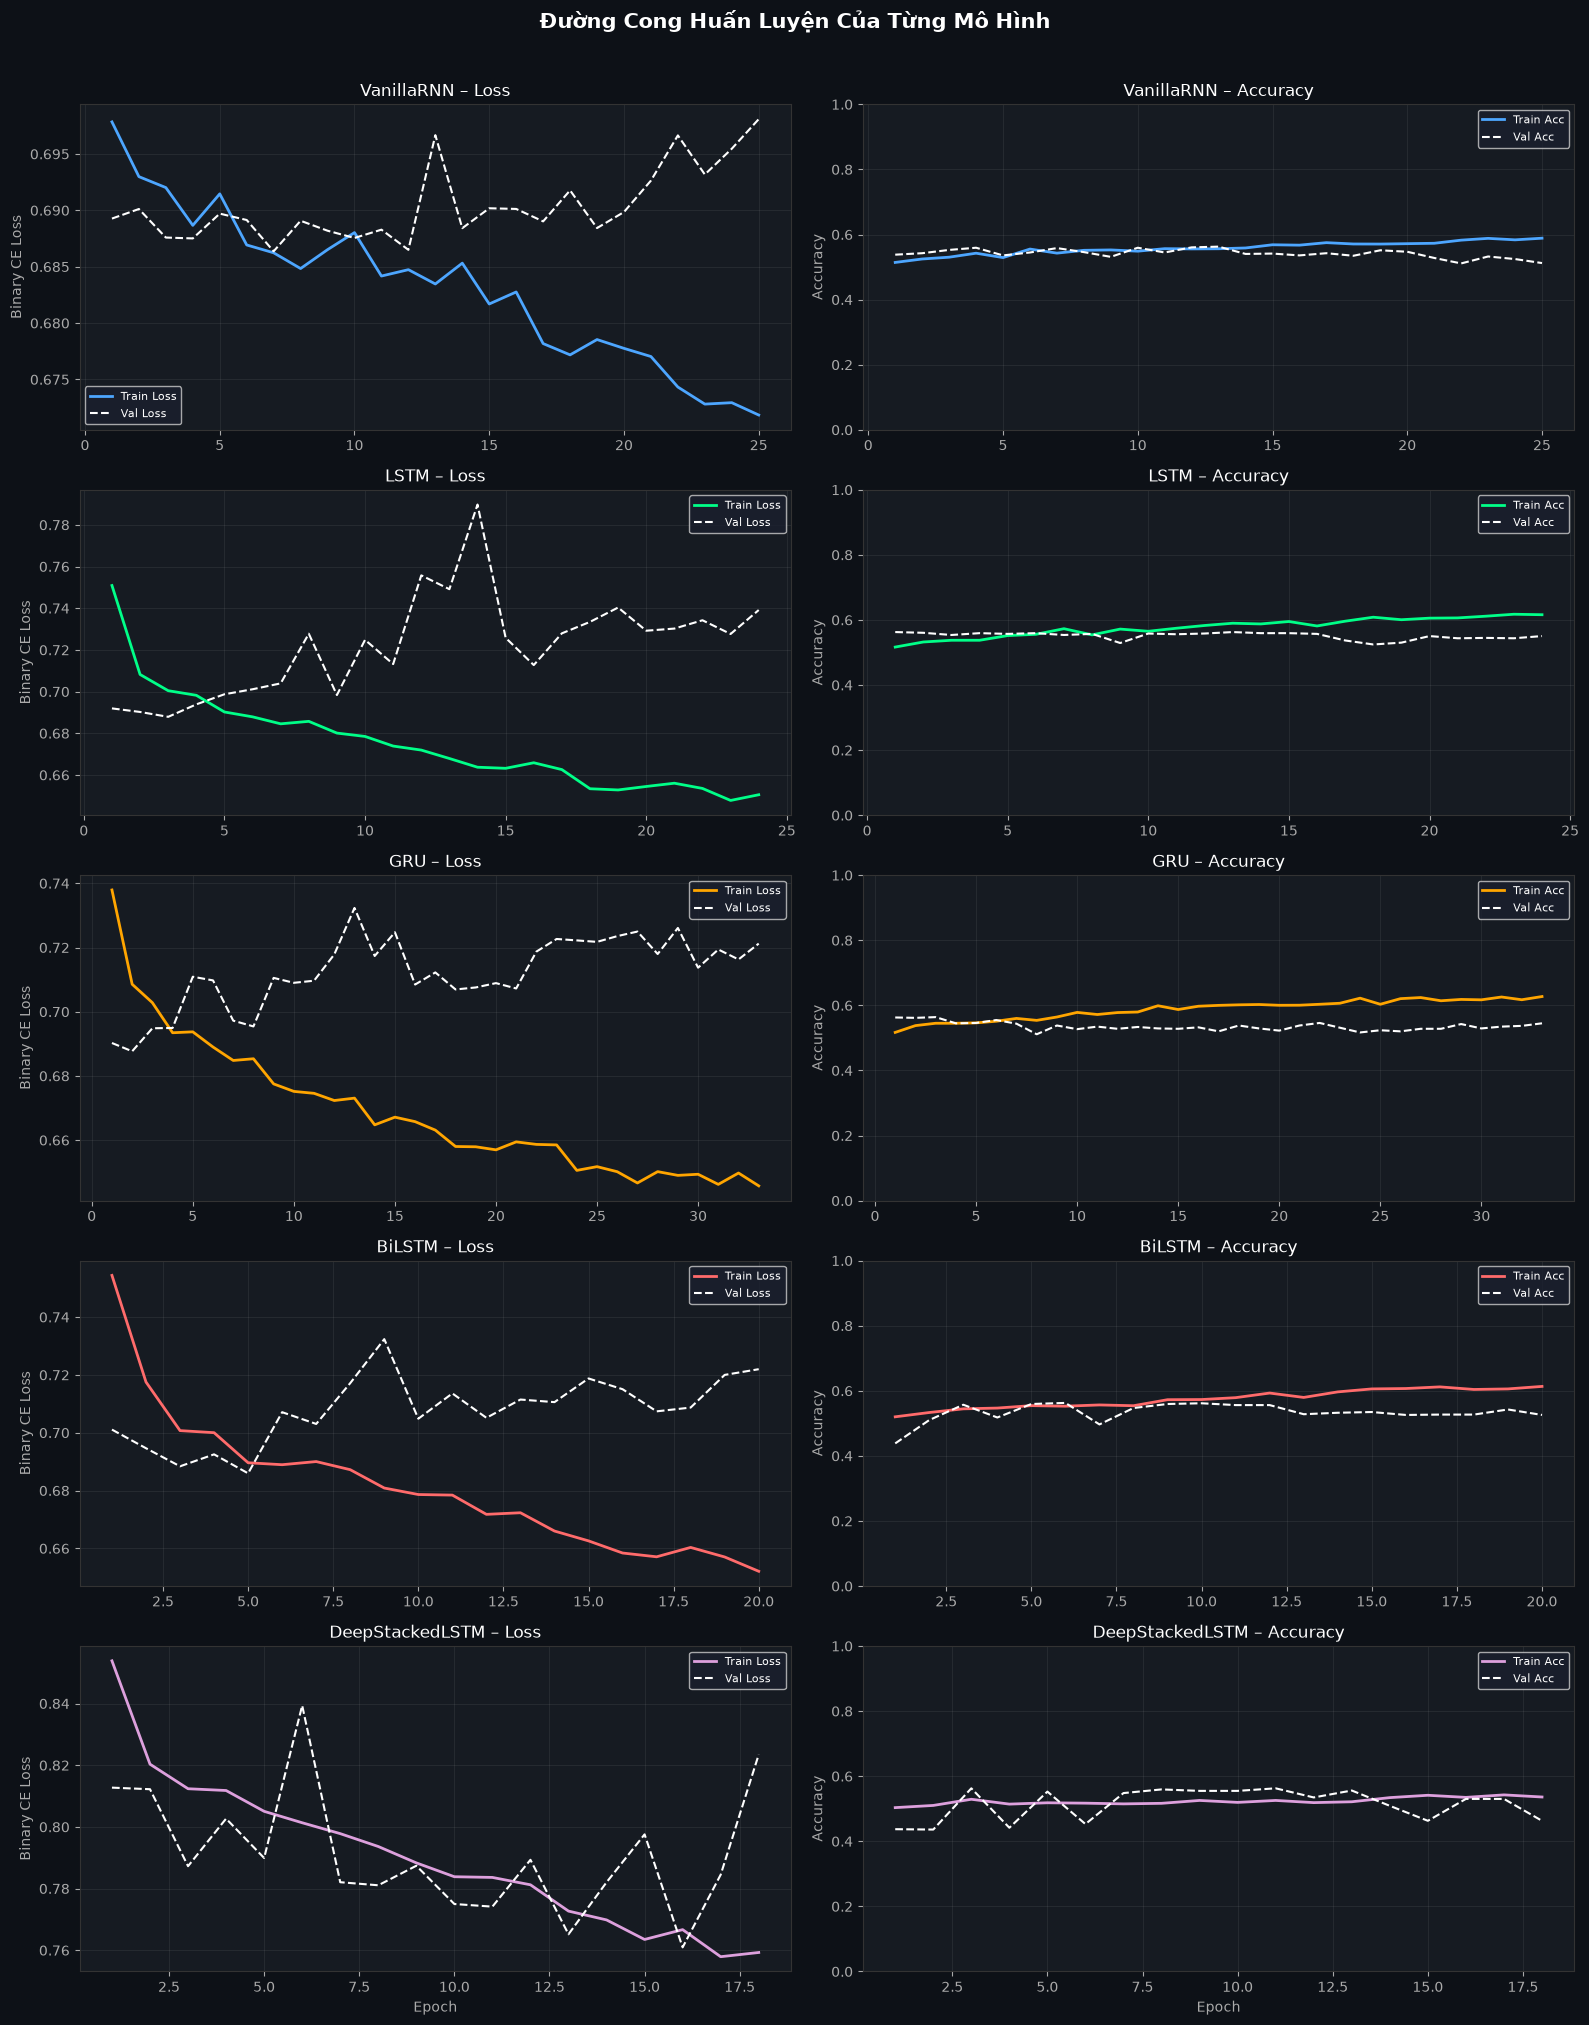

In [12]:
# ─── BIỂU ĐỒ 1: Training Curves ───
fig, axes = plt.subplots(len(models_config), 2, figsize=(16, 4*len(models_config)), 
                          facecolor='#0d1117')
fig.suptitle('Đường Cong Huấn Luyện Của Từng Mô Hình', fontsize=15, 
             color='white', fontweight='bold', y=1.01)

colors_model = {
    'VanillaRNN'     : '#4da6ff',
    'LSTM'           : '#00ff88',
    'GRU'            : '#ffa500',
    'BiLSTM'         : '#ff6b6b',
    'DeepStackedLSTM': '#dda0dd'
}

for i, (name, history) in enumerate(histories.items()):
    color = colors_model[name]
    h = history.history
    epochs_ran = range(1, len(h['loss']) + 1)
    
    for ax in axes[i]:
        ax.set_facecolor('#161b22')
        ax.tick_params(colors='#aaaaaa')
        for spine in ax.spines.values(): spine.set_color('#333')
        ax.grid(True, alpha=0.1)
    
    # Loss curve
    axes[i][0].plot(epochs_ran, h['loss'],     color=color,    lw=2, label='Train Loss')
    axes[i][0].plot(epochs_ran, h['val_loss'], color='white',  lw=1.5, linestyle='--', label='Val Loss')
    axes[i][0].set_title(f'{name} – Loss', color='white')
    axes[i][0].set_ylabel('Binary CE Loss', color='#aaaaaa')
    axes[i][0].legend(facecolor='#1a1f2e', labelcolor='white', fontsize=8)
    
    # Accuracy curve
    axes[i][1].plot(epochs_ran, h['accuracy'],     color=color,    lw=2, label='Train Acc')
    axes[i][1].plot(epochs_ran, h['val_accuracy'], color='white',  lw=1.5, linestyle='--', label='Val Acc')
    axes[i][1].set_title(f'{name} – Accuracy', color='white')
    axes[i][1].set_ylabel('Accuracy', color='#aaaaaa')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].legend(facecolor='#1a1f2e', labelcolor='white', fontsize=8)
    
    if i == len(models_config) - 1:
        axes[i][0].set_xlabel('Epoch', color='#aaaaaa')
        axes[i][1].set_xlabel('Epoch', color='#aaaaaa')

plt.tight_layout()
plt.savefig('compare_training_curves.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


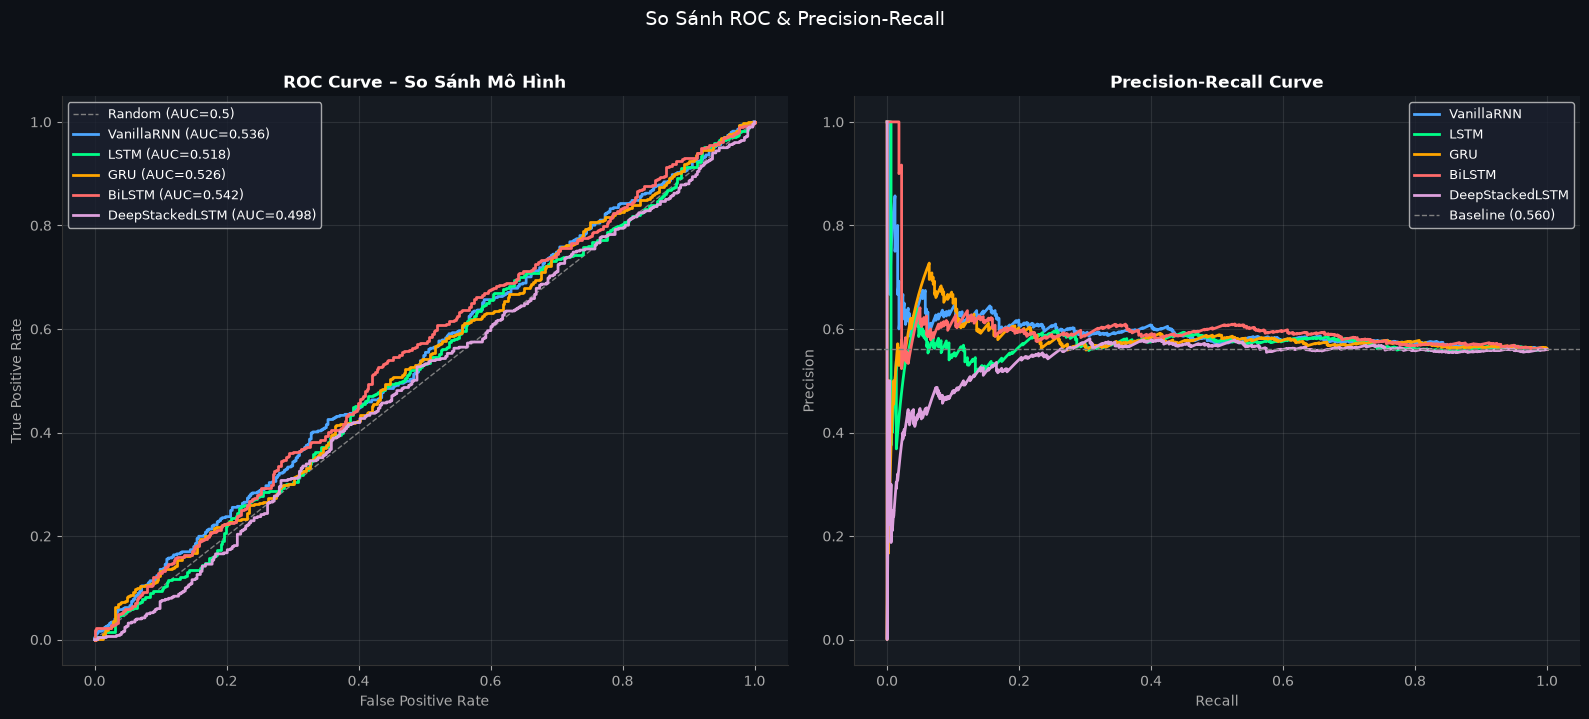

In [13]:
# ─── BIỂU ĐỒ 2: ROC Curve So Sánh ───
fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor='#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='#aaaaaa')
    ax.spines['bottom'].set_color('#333')
    ax.spines['left'].set_color('#333')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, alpha=0.15)

# ROC Curves
axes[0].plot([0,1],[0,1], color='gray', lw=1, linestyle='--', label='Random (AUC=0.5)')
for name, result in eval_results.items():
    fpr, tpr, _ = roc_curve(y_test, result['y_pred_prob'])
    axes[0].plot(fpr, tpr, color=colors_model[name], lw=2,
                 label=f"{name} (AUC={result['auc']:.3f})")
axes[0].set_xlabel('False Positive Rate', color='#aaaaaa')
axes[0].set_ylabel('True Positive Rate', color='#aaaaaa')
axes[0].set_title('ROC Curve – So Sánh Mô Hình', color='white', fontweight='bold')
axes[0].legend(facecolor='#1a1f2e', labelcolor='white', fontsize=9)

# Precision-Recall Curves
for name, result in eval_results.items():
    prec, rec, _ = precision_recall_curve(y_test, result['y_pred_prob'])
    axes[1].plot(rec, prec, color=colors_model[name], lw=2, label=f"{name}")
baseline_pr = y_test.mean()
axes[1].axhline(y=baseline_pr, color='gray', lw=1, linestyle='--', 
                label=f'Baseline ({baseline_pr:.3f})')
axes[1].set_xlabel('Recall', color='#aaaaaa')
axes[1].set_ylabel('Precision', color='#aaaaaa')
axes[1].set_title('Precision-Recall Curve', color='white', fontweight='bold')
axes[1].legend(facecolor='#1a1f2e', labelcolor='white', fontsize=9)

plt.suptitle('So Sánh ROC & Precision-Recall', fontsize=14, color='white', y=1.02)
plt.tight_layout()
plt.savefig('compare_roc_pr.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


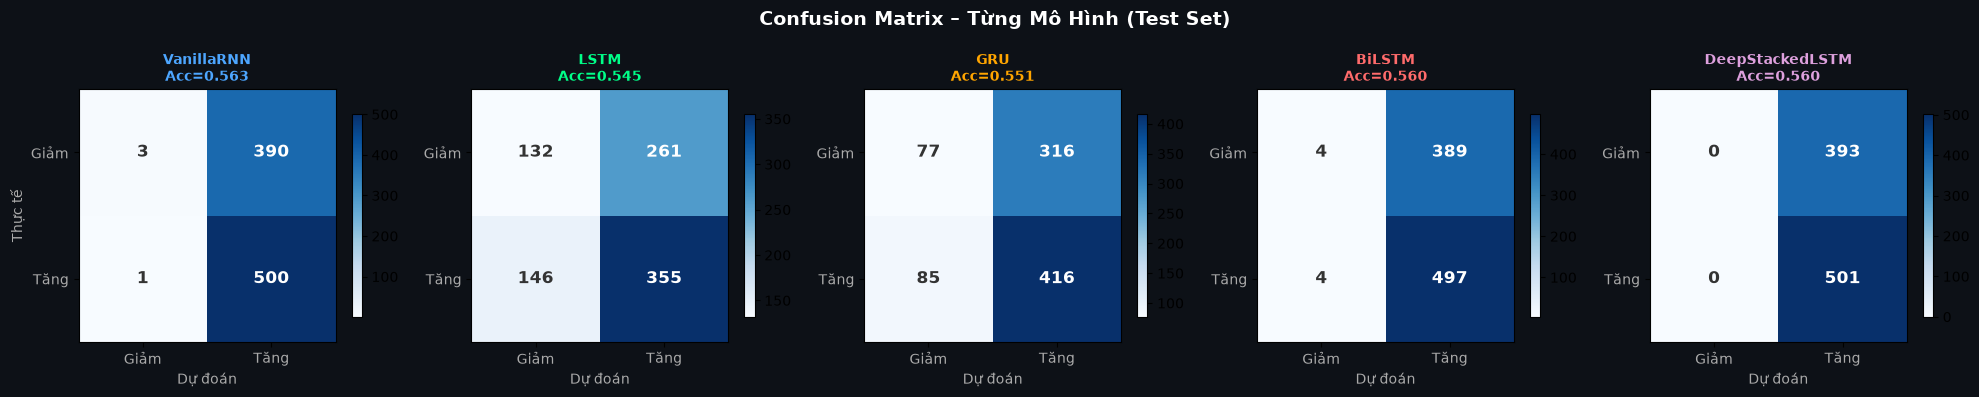

In [14]:
# ─── BIỂU ĐỒ 3: Confusion Matrix tất cả mô hình ───
fig, axes = plt.subplots(1, len(models_config), figsize=(20, 4), facecolor='#0d1117')
fig.suptitle('Confusion Matrix – Từng Mô Hình (Test Set)', fontsize=14, 
             color='white', fontweight='bold')

for idx, (name, result) in enumerate(eval_results.items()):
    cm = confusion_matrix(y_test, result['y_pred'])
    axes[idx].set_facecolor('#161b22')
    
    im = axes[idx].imshow(cm, cmap='Blues', aspect='auto')
    axes[idx].set_xticks([0,1]); axes[idx].set_yticks([0,1])
    axes[idx].set_xticklabels(['Giảm','Tăng'], color='#aaaaaa')
    axes[idx].set_yticklabels(['Giảm','Tăng'], color='#aaaaaa')
    axes[idx].set_xlabel('Dự đoán', color='#aaaaaa')
    if idx == 0: axes[idx].set_ylabel('Thực tế', color='#aaaaaa')
    axes[idx].set_title(f"{name}\nAcc={result['accuracy']:.3f}", 
                         color=colors_model[name], fontsize=10, fontweight='bold')
    
    # Thêm số vào ô
    for i in range(2):
        for j in range(2):
            axes[idx].text(j, i, str(cm[i,j]),
                          ha='center', va='center', fontsize=12,
                          color='white' if cm[i,j] > cm.max()/2 else '#333',
                          fontweight='bold')
    plt.colorbar(im, ax=axes[idx], shrink=0.8)

plt.tight_layout()
plt.savefig('compare_confusion_matrix.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()



📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ MÔ HÌNH
        Mô Hình Accuracy AUC-ROC F1 Score Train Time
     VanillaRNN   0.5626  0.5358   0.7189      21.7s
           LSTM   0.5447  0.5184   0.6356      66.7s
            GRU   0.5515  0.5264   0.6748      98.6s
         BiLSTM   0.5604  0.5425   0.7167      53.7s
DeepStackedLSTM   0.5604  0.4976   0.7183     158.4s


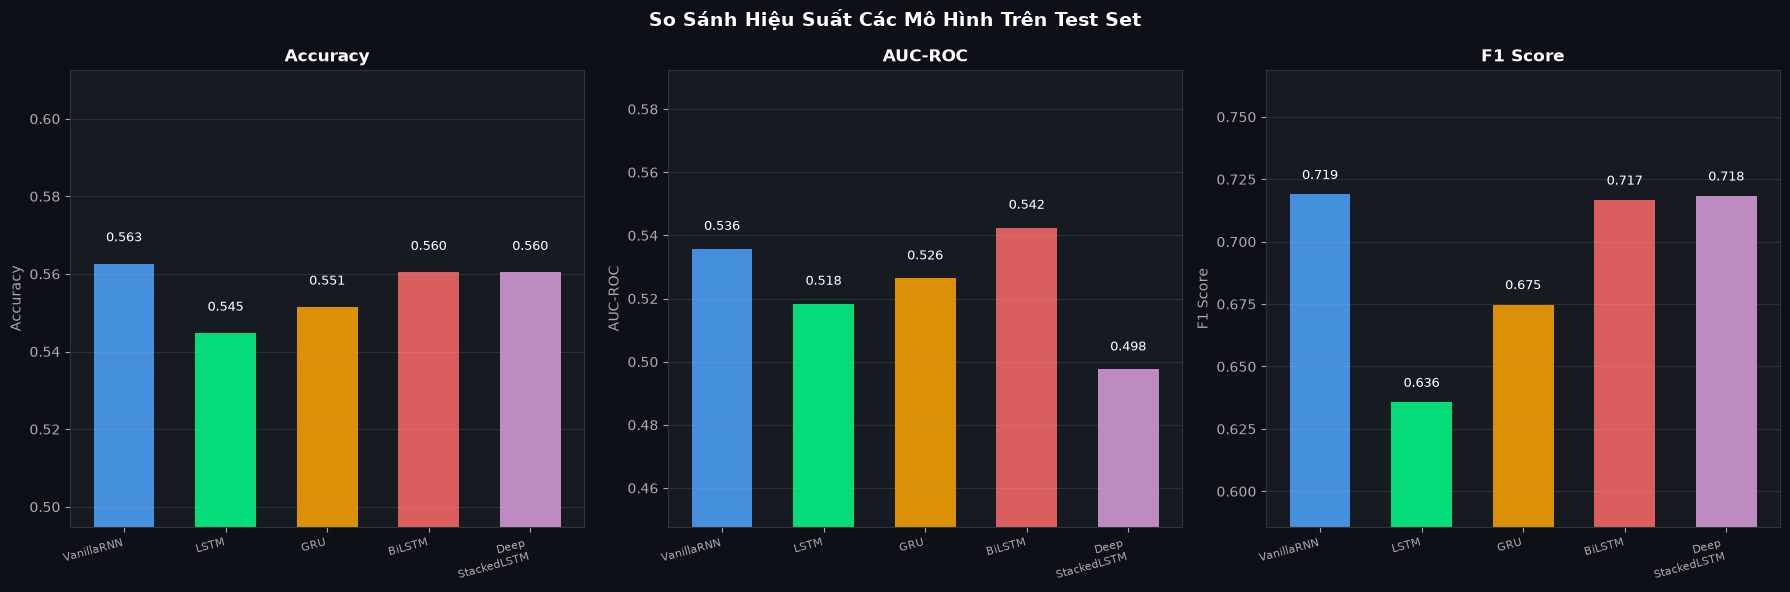

In [15]:
# ─── BIỂU ĐỒ 4: Bảng tổng hợp + Bar chart ───
print("\n" + "="*65)
print("📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ MÔ HÌNH")
print("="*65)

summary_df = pd.DataFrame([
    {
        'Mô Hình'    : name,
        'Accuracy'   : f"{r['accuracy']:.4f}",
        'AUC-ROC'    : f"{r['auc']:.4f}",
        'F1 Score'   : f"{r['f1']:.4f}",
        'Train Time' : f"{training_times[name]:.1f}s"
    }
    for name, r in eval_results.items()
])
print(summary_df.to_string(index=False))

# Bar chart so sánh metrics
metrics_names = ['accuracy', 'auc', 'f1']
metrics_labels = ['Accuracy', 'AUC-ROC', 'F1 Score']

fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor='#0d1117')
fig.suptitle('So Sánh Hiệu Suất Các Mô Hình Trên Test Set', 
             fontsize=14, color='white', fontweight='bold')

for ax_idx, (metric, label) in enumerate(zip(metrics_names, metrics_labels)):
    ax = axes[ax_idx]
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='#aaaaaa')
    for spine in ax.spines.values(): spine.set_color('#333')
    ax.grid(True, alpha=0.15, axis='y')
    
    values = [eval_results[n][metric] for n in models_config.keys()]
    bar_colors = [colors_model[n] for n in models_config.keys()]
    names = list(models_config.keys())
    
    bars = ax.bar(range(len(names)), values, color=bar_colors, alpha=0.85, 
                  edgecolor='none', width=0.6)
    
    # Ghi giá trị
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', color='white', fontsize=9)
    
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace('Stacked','\nStacked') for n in names], 
                        rotation=15, ha='right', fontsize=8)
    ax.set_title(label, color='white', fontweight='bold')
    ax.set_ylabel(label, color='#aaaaaa')
    ymin = max(0, min(values) - 0.05)
    ax.set_ylim(ymin, min(1.0, max(values) + 0.05))

plt.tight_layout()
plt.savefig('compare_metrics_bar.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## 10. 🎯 Phân Tích Chi Tiết Mô Hình Tốt Nhất

> Phân tích sâu mô hình có AUC cao nhất: **classification report**, dự đoán xác suất theo thời gian, và đường cong tích lũy lợi nhuận.


In [16]:
# Classification Report chi tiết
print(f"\n🏆 Mô hình tốt nhất: {best_model_name}")
print("="*55)
best_preds = eval_results[best_model_name]
print(classification_report(y_test, best_preds['y_pred'], 
      target_names=['Giảm (0)', 'Tăng (1)'], digits=4))



🏆 Mô hình tốt nhất: BiLSTM
              precision    recall  f1-score   support

    Giảm (0)     0.5000    0.0102    0.0200       393
    Tăng (1)     0.5609    0.9920    0.7167       501

    accuracy                         0.5604       894
   macro avg     0.5305    0.5011    0.3683       894
weighted avg     0.5342    0.5604    0.4104       894



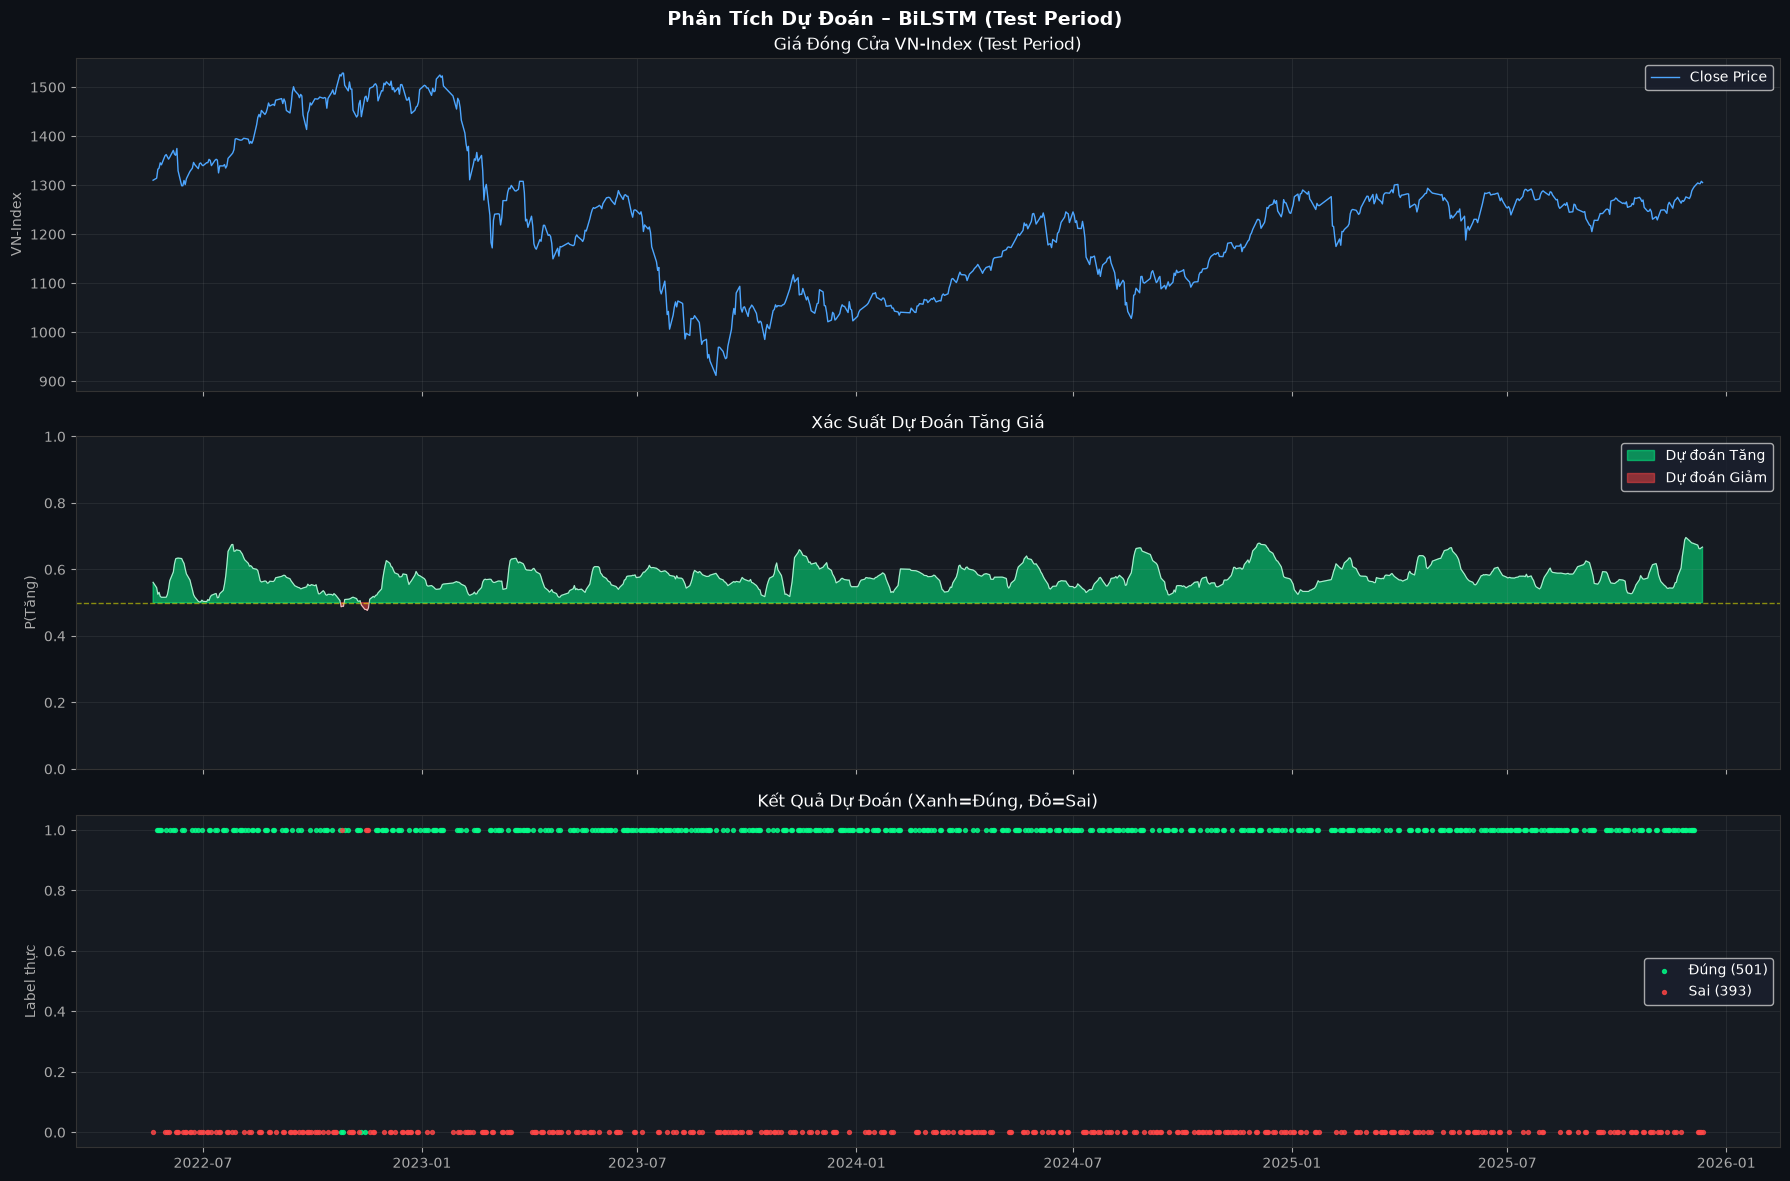

In [17]:
# Biểu đồ dự đoán xác suất theo thời gian (test period)
test_dates = df_feat['date'].iloc[n_train + n_val + LOOKBACK:].reset_index(drop=True)
test_close  = df_raw['close'].iloc[n_train + n_val + LOOKBACK:].reset_index(drop=True)

# Điều chỉnh kích thước
min_len = min(len(test_dates), len(best_preds['y_pred_prob']), len(test_close))
test_dates    = test_dates[:min_len]
test_close_  = test_close[:min_len]
prob_series   = best_preds['y_pred_prob'][:min_len]
pred_series   = best_preds['y_pred'][:min_len]
actual_series = y_test[:min_len]

fig, axes = plt.subplots(3, 1, figsize=(18, 12), facecolor='#0d1117', sharex=True)
fig.suptitle(f'Phân Tích Dự Đoán – {best_model_name} (Test Period)', 
             fontsize=14, color='white', fontweight='bold')

for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='#aaaaaa')
    for sp in ax.spines.values(): sp.set_color('#333')
    ax.grid(True, alpha=0.1)

# Giá thực tế
axes[0].plot(test_dates, test_close_, color='#4da6ff', lw=1, label='Close Price')
axes[0].set_ylabel('VN-Index', color='#aaaaaa')
axes[0].set_title('Giá Đóng Cửa VN-Index (Test Period)', color='white')
axes[0].legend(facecolor='#1a1f2e', labelcolor='white')

# Xác suất tăng
axes[1].fill_between(test_dates, prob_series, 0.5, 
                      where=(prob_series >= 0.5), 
                      color='#00ff88', alpha=0.5, label='Dự đoán Tăng')
axes[1].fill_between(test_dates, prob_series, 0.5, 
                      where=(prob_series < 0.5), 
                      color='#ff4444', alpha=0.5, label='Dự đoán Giảm')
axes[1].plot(test_dates, prob_series, color='white', lw=0.8, alpha=0.7)
axes[1].axhline(0.5, color='yellow', lw=1, linestyle='--', alpha=0.5)
axes[1].set_ylabel('P(Tăng)', color='#aaaaaa')
axes[1].set_title('Xác Suất Dự Đoán Tăng Giá', color='white')
axes[1].legend(facecolor='#1a1f2e', labelcolor='white')
axes[1].set_ylim(0, 1)

# Đúng/Sai prediction
correct = (pred_series == actual_series.astype(int))
axes[2].scatter(test_dates[correct], actual_series[correct], 
               color='#00ff88', s=8, alpha=0.8, label=f'Đúng ({correct.sum()})')
axes[2].scatter(test_dates[~correct], actual_series[~correct], 
               color='#ff4444', s=8, alpha=0.8, label=f'Sai ({(~correct).sum()})')
axes[2].set_ylabel('Label thực', color='#aaaaaa')
axes[2].set_title('Kết Quả Dự Đoán (Xanh=Đúng, Đỏ=Sai)', color='white')
axes[2].legend(facecolor='#1a1f2e', labelcolor='white')

plt.tight_layout()
plt.savefig('best_model_prediction.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()



📈 Buy & Hold Return: -0.36%
🤖 Model Strategy Return: -5.84%
🔴 Buy & Hold better


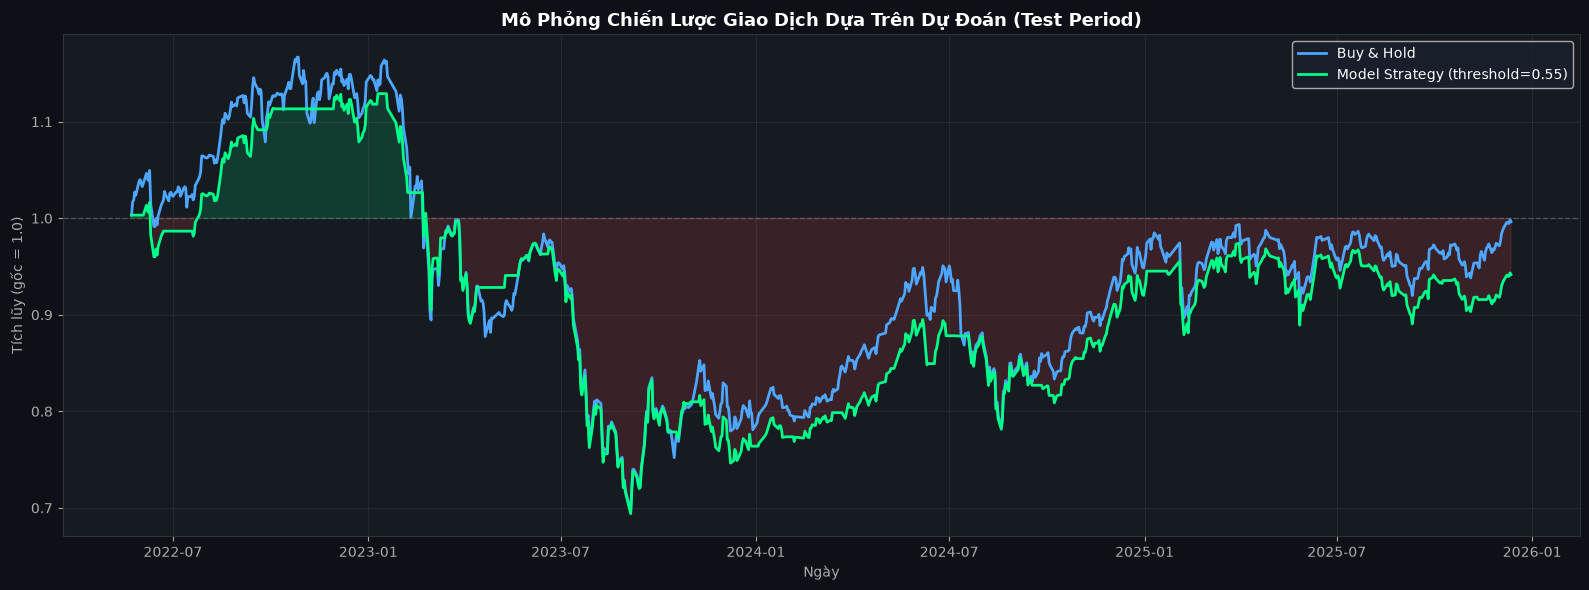

In [18]:
# ─── Mô phỏng chiến lược giao dịch đơn giản ───
# Giả sử: mua nếu P(Tăng) > 0.55, giữ cash nếu không
THRESHOLD = 0.55
returns_actual  = np.diff(test_close_.values) / test_close_.values[:-1]

# Chiến lược model: mua khi model dự đoán tăng
strategy_pos = (prob_series[:-1] >= THRESHOLD).astype(float)
strategy_ret = strategy_pos * returns_actual

# Buy & Hold
bh_cumret       = np.cumprod(1 + returns_actual)
strategy_cumret = np.cumprod(1 + strategy_ret)

fig, ax = plt.subplots(figsize=(16, 6), facecolor='#0d1117')
ax.set_facecolor('#161b22')
ax.tick_params(colors='#aaaaaa')
for sp in ax.spines.values(): sp.set_color('#333')
ax.grid(True, alpha=0.1)

ax.plot(test_dates[1:], bh_cumret,       color='#4da6ff', lw=2, label='Buy & Hold')
ax.plot(test_dates[1:], strategy_cumret, color='#00ff88', lw=2, label=f'Model Strategy (threshold={THRESHOLD})')
ax.axhline(1.0, color='gray', lw=1, linestyle='--', alpha=0.5)
ax.fill_between(test_dates[1:], strategy_cumret, 1.0,
                where=(strategy_cumret >= 1), alpha=0.15, color='#00ff88')
ax.fill_between(test_dates[1:], strategy_cumret, 1.0,
                where=(strategy_cumret < 1), alpha=0.15, color='#ff4444')
ax.set_xlabel('Ngày', color='#aaaaaa')
ax.set_ylabel('Tích lũy (gốc = 1.0)', color='#aaaaaa')
ax.set_title('Mô Phỏng Chiến Lược Giao Dịch Dựa Trên Dự Đoán (Test Period)', 
             color='white', fontsize=13, fontweight='bold')
ax.legend(facecolor='#1a1f2e', labelcolor='white')

final_bh  = bh_cumret[-1]
final_str = strategy_cumret[-1]
print(f"\n📈 Buy & Hold Return: {(final_bh-1)*100:.2f}%")
print(f"🤖 Model Strategy Return: {(final_str-1)*100:.2f}%")
print(f"{'🟢 Model outperformed!' if final_str > final_bh else '🔴 Buy & Hold better'}")

plt.tight_layout()
plt.savefig('strategy_comparison.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## 11. 📝 Kết Luận & Tóm Tắt

### So Sánh Kiến Trúc

| Mô hình | Ưu điểm | Nhược điểm | Phù hợp khi |
|---------|---------|-----------|------------|
| **Vanilla RNN** | Đơn giản, nhanh | Vanishing gradient, kém với chuỗi dài | Baseline, chuỗi rất ngắn |
| **LSTM** | Học phụ thuộc dài, ổn định | Nhiều tham số, chậm hơn GRU | Hầu hết bài toán TS |
| **GRU** | Nhẹ hơn LSTM, hội tụ nhanh | Kém LSTM trên chuỗi rất dài | Dữ liệu hạn chế, RT |
| **BiLSTM** | Học 2 chiều, pattern phong phú | Không phù hợp real-time predict | Phân tích offline |
| **Deep Stacked LSTM** | Biểu diễn phong phú nhất | Cần nhiều dữ liệu, train lâu | Bài toán phức tạp, dữ liệu lớn |

### Kết Quả Thực Nghiệm
> Xem bảng `summary_df` ở trên cho số liệu chi tiết.

### Các file đã lưu:
- `models/best_model.keras` — Mô hình tốt nhất
- `models/scaler.pkl` — MinMaxScaler đã fit
- `models/feature_cols.pkl` — Danh sách features
- `models/metadata.json` — Metadata & evaluation results
- `models/DeepStackedLSTM.keras` (và các mô hình khác)

### Bước Tiếp Theo:
- Deploy Web App tại `webapp/` — chạy `python webapp/app.py`
